# ❤️ Heart Disease Risk Prediction — End-to-End Machine Learning Pipeline

**Dataset:** UCI Heart Disease (Kaggle `heart.csv` — 1,025 records, 13 clinical features; 302 unique patients after de-duplication)  
**Objective:** Binary classification — predict presence of heart disease (`target = 1`)  
**Pipeline:** Preprocessing → EDA → Train/Test Split → Feature Engineering → SMOTE → Scaling → RFECV → Hyperparameter Tuning → Stacking → Evaluation → SHAP & LIME → Actionable Explanations → Model Export

**Author:** Tawananyasha Nigel Chinembiri — University of Zimbabwe, Department of Analytics and Informatics  
**Supervisor:** Mr. Zimowa

> Run all cells top-to-bottom from the project root. Figures are written to `figures/`, fitted artefacts to `models/` and the metrics table to `reports/`. The Streamlit app (`app.py`) loads these artefacts.

---

## 1. 🔧 Environment Setup & Library Imports

In [42]:
# ── Standard ──────────────────────────────────────────────────────────────────
import os, sys, json, warnings
warnings.filterwarnings("ignore")

# ── Numerical / Data ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Scikit-learn ──────────────────────────────────────────────────────────────
from sklearn.model_selection  import (train_test_split, GridSearchCV,
                                      StratifiedKFold, cross_val_score)
from sklearn.preprocessing    import StandardScaler
from sklearn.impute           import SimpleImputer
from sklearn.pipeline         import Pipeline
from sklearn.feature_selection import RFECV
from sklearn.linear_model     import LogisticRegression
from sklearn.ensemble         import (RandomForestClassifier,
                                      StackingClassifier)
from sklearn.svm              import SVC
from sklearn.metrics          import (accuracy_score, precision_score,
                                      recall_score, f1_score, roc_auc_score,
                                      matthews_corrcoef, confusion_matrix,
                                      ConfusionMatrixDisplay, roc_curve,
                                      precision_recall_curve,
                                      average_precision_score)

# ── XGBoost ───────────────────────────────────────────────────────────────────
from xgboost import XGBClassifier

# ── Imbalanced-learn ──────────────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

# ── Explainability ────────────────────────────────────────────────────────────
import shap
import lime
import lime.lime_tabular

# ── Project helpers ───────────────────────────────────────────────────────────
import joblib
from heart_utils import (FEATURE_NAMES, FEATURE_LABELS, CONTINUOUS_COLS,
                         ACTION_MAP, add_features)

# ── Global Settings ───────────────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot style — light theme (readable in notebook, README and print)
INK = "#111827"
plt.rcParams.update({
    "figure.facecolor":  "white",
    "savefig.facecolor": "white",
    "axes.facecolor":    "white",
    "axes.edgecolor":    "#9ca3af",
    "axes.labelcolor":   INK,
    "axes.titlecolor":   INK,
    "xtick.color":       INK,
    "ytick.color":       INK,
    "text.color":        INK,
    "legend.facecolor":  "white",
    "legend.edgecolor":  "#d1d5db",
    "legend.labelcolor": INK,
    "grid.color":        "#d1d5db",
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "figure.dpi":        110,
    "axes.titlesize":    14,
    "axes.labelsize":    12,
    "legend.fontsize":   10,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
})

FIGURES_DIR = "figures"
MODELS_DIR  = "models"
REPORTS_DIR = "reports"
for d in (FIGURES_DIR, MODELS_DIR, REPORTS_DIR):
    os.makedirs(d, exist_ok=True)

print("✅ All imports successful.")
print(f"📁 Figures will be saved to ./{FIGURES_DIR}/")

✅ All imports successful.
📁 Figures will be saved to ./figures/


---
## 2. 🗂️ Data Loading & Preprocessing

In [43]:
# ── Load Dataset ──────────────────────────────────────────────────────────────
df = pd.read_csv("data/heart.csv")

# ── Remove Duplicate Rows ─────────────────────────────────────────────────────
n_before = len(df)
df = df.drop_duplicates()
df = df.reset_index(drop=True)
n_after  = len(df)
print(f"Duplicates removed : {n_before - n_after}  ({n_before} → {n_after} rows)")

# Keep numeric dtypes — do NOT cast to category before ML steps
X = df[FEATURE_NAMES].copy()
y = df["target"].copy()

print("Dataset shape :", df.shape)
print("Class balance  :", dict(y.value_counts().rename({0: 'No Disease', 1: 'Disease'})))
print("Missing values :", X.isnull().sum().sum())
df.head()

Duplicates removed : 723  (1025 → 302 rows)
Dataset shape : (302, 14)
Class balance  : {'Disease': np.int64(164), 'No Disease': np.int64(138)}
Missing values : 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [44]:
# ── Statistical Summary ───────────────────────────────────────────────────────
summary = df.describe().T
summary.style \
    .background_gradient(cmap="Blues", axis=None) \
    .format(precision=2) \
    .set_caption("Statistical Summary of All Features")

,count,mean,std,min,25%,50%,75%,max
age,302.00,54.42,9.05,29.00,48.00,55.50,61.00,77.00
sex,302.00,0.68,0.47,0.00,0.00,1.00,1.00,1.00
cp,302.00,0.96,1.03,0.00,0.00,1.00,2.00,3.00
trestbps,302.00,131.60,17.56,94.00,120.00,130.00,140.00,200.00
chol,302.00,246.50,51.75,126.00,211.00,240.50,274.75,564.00
fbs,302.00,0.15,0.36,0.00,0.00,0.00,0.00,1.00
restecg,302.00,0.53,0.53,0.00,0.00,1.00,1.00,2.00
thalach,302.00,149.57,22.90,71.00,133.25,152.50,166.00,202.00
exang,302.00,0.33,0.47,0.00,0.00,0.00,1.00,1.00
oldpeak,302.00,1.04,1.16,0.00,0.00,0.80,1.60,6.20


In [45]:
# ── Missing Values & Data Types ───────────────────────────────────────────────
info_df = pd.DataFrame({
    "dtype":   df.dtypes,
    "missing": df.isnull().sum(),
    "missing%": (df.isnull().sum() / len(df) * 100).round(2),
    "unique":  df.nunique()
})
print(info_df.to_string())

            dtype  missing  missing%  unique
age         int64        0       0.0      41
sex         int64        0       0.0       2
cp          int64        0       0.0       4
trestbps    int64        0       0.0      49
chol        int64        0       0.0     152
fbs         int64        0       0.0       2
restecg     int64        0       0.0       3
thalach     int64        0       0.0      91
exang       int64        0       0.0       2
oldpeak   float64        0       0.0      40
slope       int64        0       0.0       3
ca          int64        0       0.0       5
thal        int64        0       0.0       4
target      int64        0       0.0       2


---
## 3. 📊 Feature Distribution

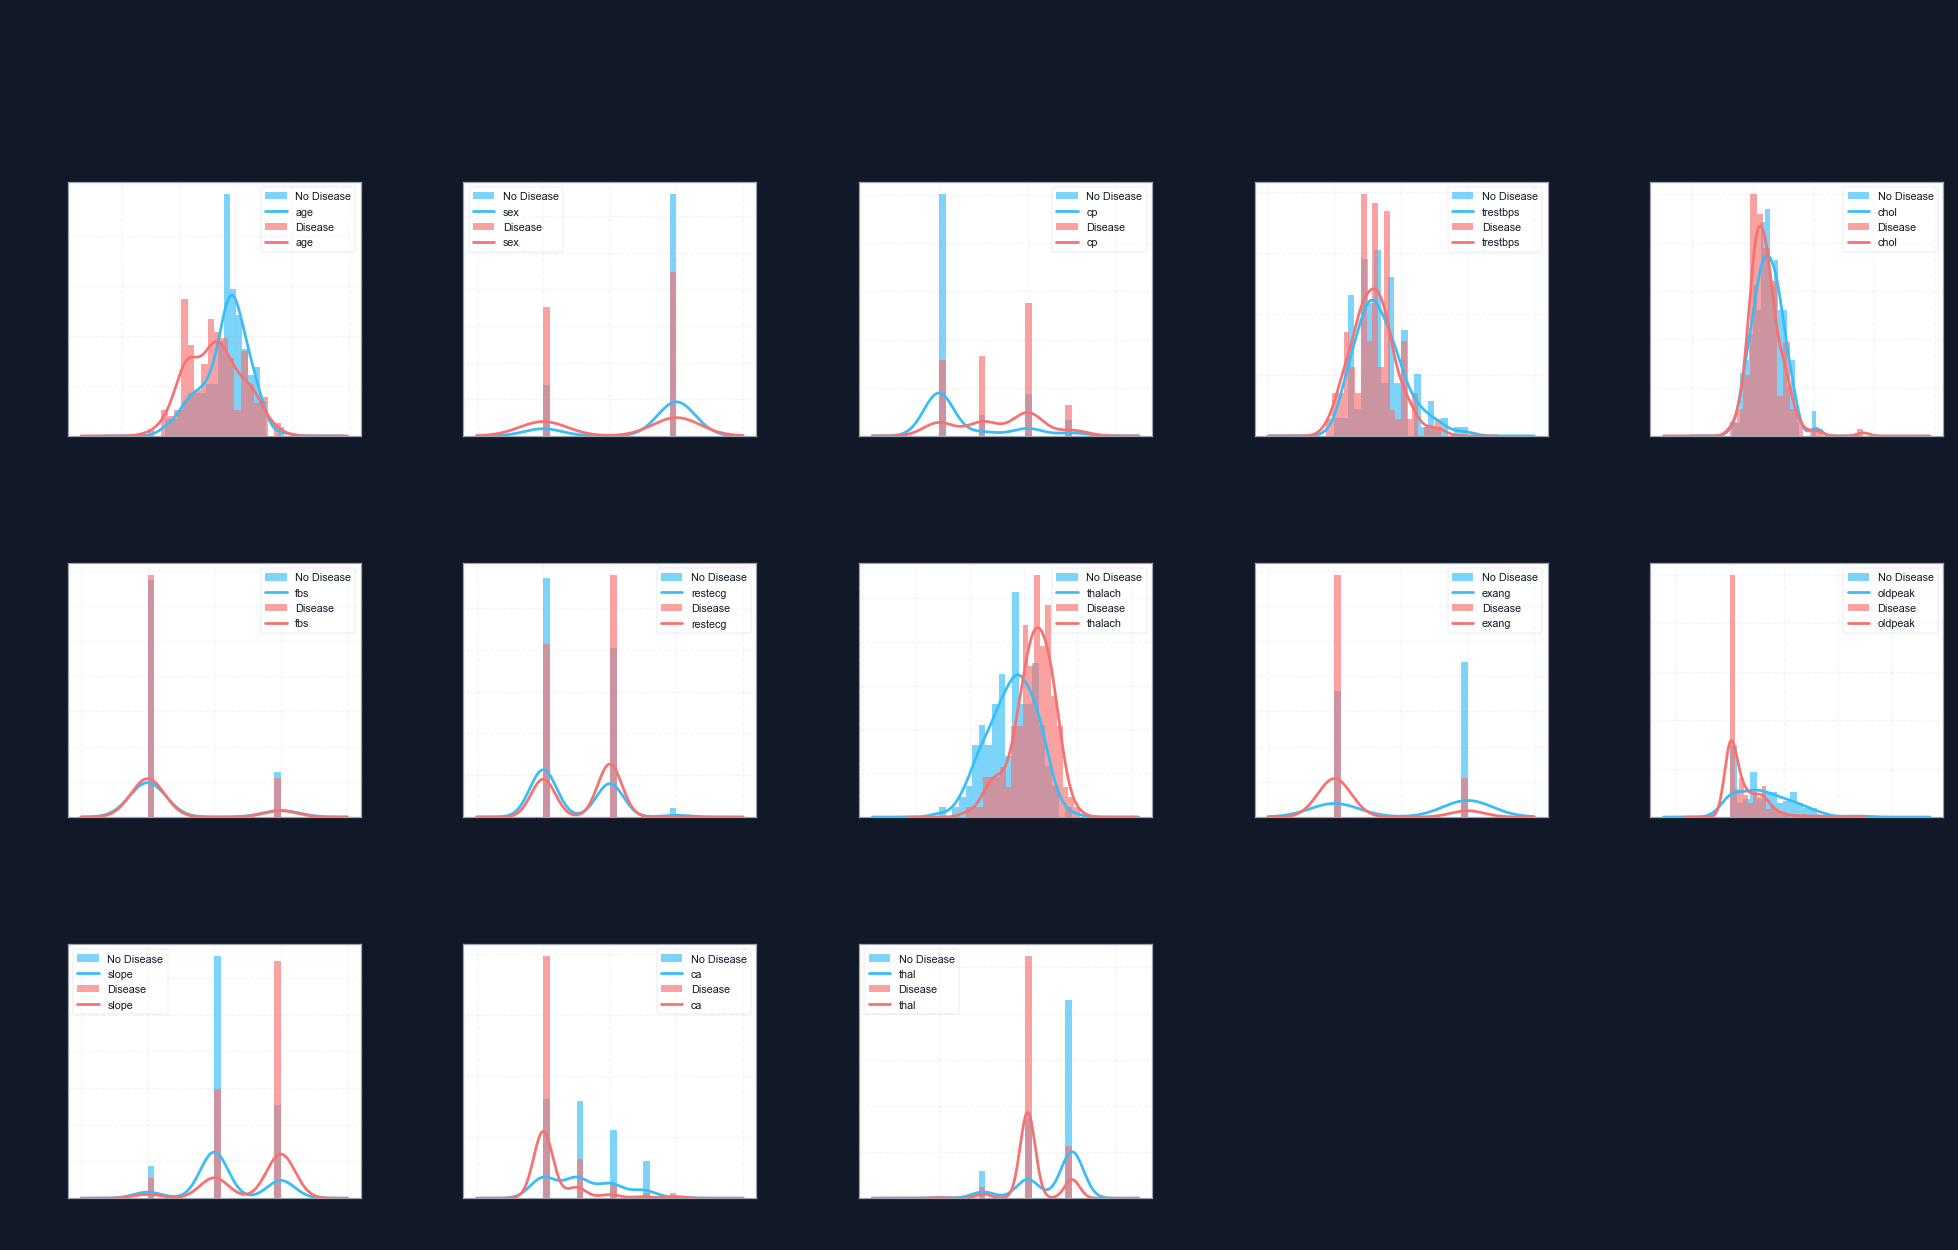

💾 Saved: feature_distributions_by_target.png


In [46]:
# ── Histograms by Target ──────────────────────────────────────────────────────
PALETTE = {0: "#38bdf8", 1: "#f87171"}

fig, axes = plt.subplots(3, 5, figsize=(22, 12),
                         facecolor=INK,
                         gridspec_kw={"hspace": 0.5, "wspace": 0.35})
axes = axes.flatten()

for ax, col in zip(axes, FEATURE_NAMES):
    for label, color in PALETTE.items():
        subset = df[df["target"] == label][col]
        ax.hist(subset, bins=20, alpha=0.65, color=color, edgecolor="none",
                label="No Disease" if label == 0 else "Disease", density=True)
        subset.plot.kde(ax=ax, color=color, linewidth=1.8)
    ax.set_title(FEATURE_LABELS.get(col, col), fontsize=10, color=INK, pad=4)
    ax.set_xlabel("Value", fontsize=8)
    ax.set_ylabel("Density", fontsize=8)
    ax.legend(fontsize=7, framealpha=0.3)
    ax.grid(True, alpha=0.25)

# Hide unused axes
for ax in axes[len(FEATURE_NAMES):]:
    ax.set_visible(False)

fig.suptitle("Feature Distributions by Heart Disease Status",
             fontsize=16, fontweight="bold", color=INK, y=1.01)
plt.savefig(f"{FIGURES_DIR}/feature_distributions_by_target.png",
            bbox_inches="tight", facecolor=INK)
plt.show()
print("💾 Saved: feature_distributions_by_target.png")

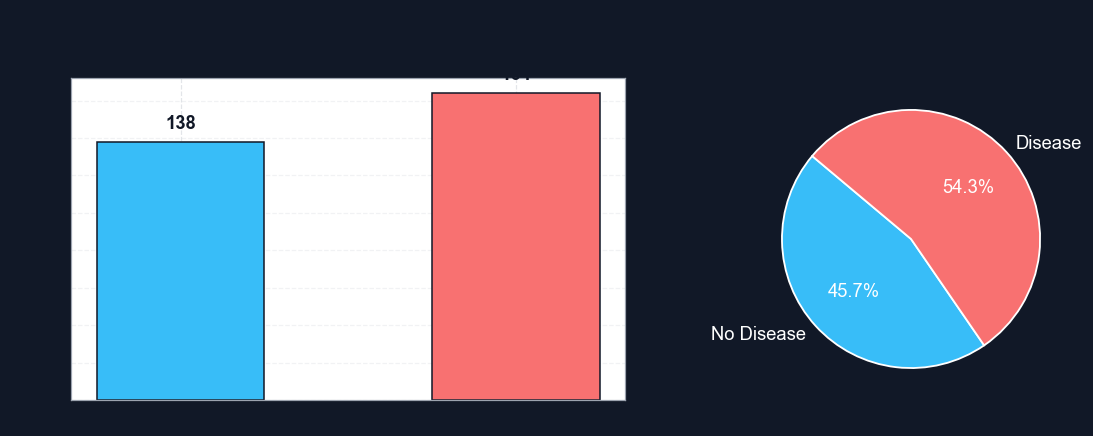

💾 Saved: class_distribution.png


In [47]:
# ── Class Distribution Bar ────────────────────────────────────────────────────
counts = y.value_counts().rename({0: "No Disease", 1: "Disease"}).reindex(["No Disease", "Disease"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=INK)

bars = axes[0].bar(counts.index, counts.values,
                   color=["#38bdf8", "#f87171"], edgecolor=INK, width=0.5)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                 str(val), ha="center", va="bottom", fontsize=12,
                 color=INK, fontweight="bold")
axes[0].set_title("Class Frequency", color=INK, fontsize=13)
axes[0].set_ylabel("Count", color=INK)
axes[0].grid(axis="y", alpha=0.3)

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=["#38bdf8", "#f87171"], startangle=140,
            wedgeprops={"edgecolor": "white", "linewidth": 1.2},
            textprops={"color": "white", "fontsize": 12})
axes[1].set_title("Class Proportion", color=INK, fontsize=13)

fig.suptitle("Target Variable — Class Distribution",
             fontsize=14, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/class_distribution.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: class_distribution.png")

---
## 4. 🏷️ Handling Categorical Values

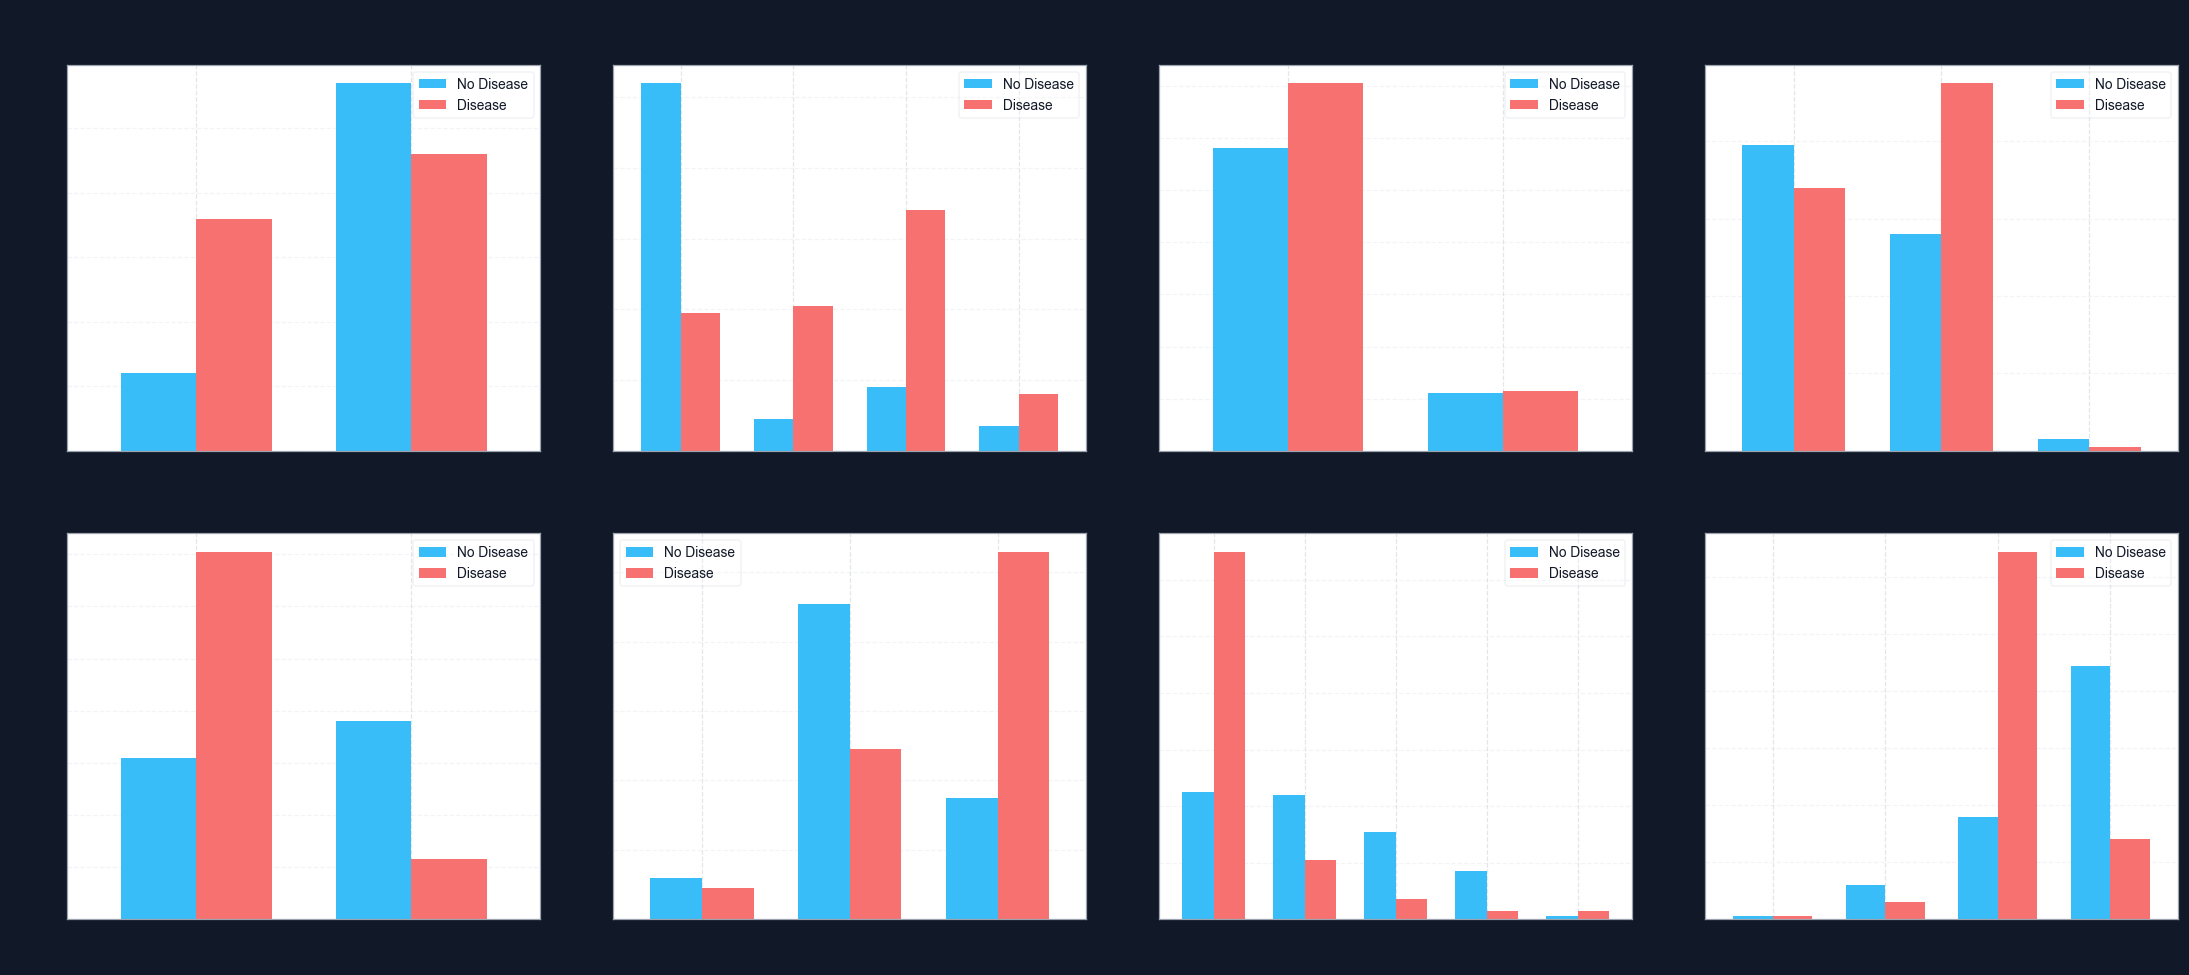

💾 Saved: categorical_features_vs_target.png


In [48]:
# Categorical features in this dataset are ordinal integers
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9), facecolor=INK)
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    ct = df.groupby([col, "target"]).size().unstack(fill_value=0)
    ct.columns = ["No Disease", "Disease"]
    ct.plot(kind="bar", ax=ax, color=["#38bdf8", "#f87171"],
            edgecolor="none", width=0.7)
    ax.set_title(f"{FEATURE_LABELS.get(col, col)}", fontsize=11, color=INK)
    ax.set_xlabel("Value", fontsize=9)
    ax.set_ylabel("Count", fontsize=9)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=9, framealpha=0.3)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Categorical Features vs Heart Disease Status",
             fontsize=15, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/categorical_features_vs_target.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: categorical_features_vs_target.png")

---
## 5. 🔍 Exploratory Data Analysis

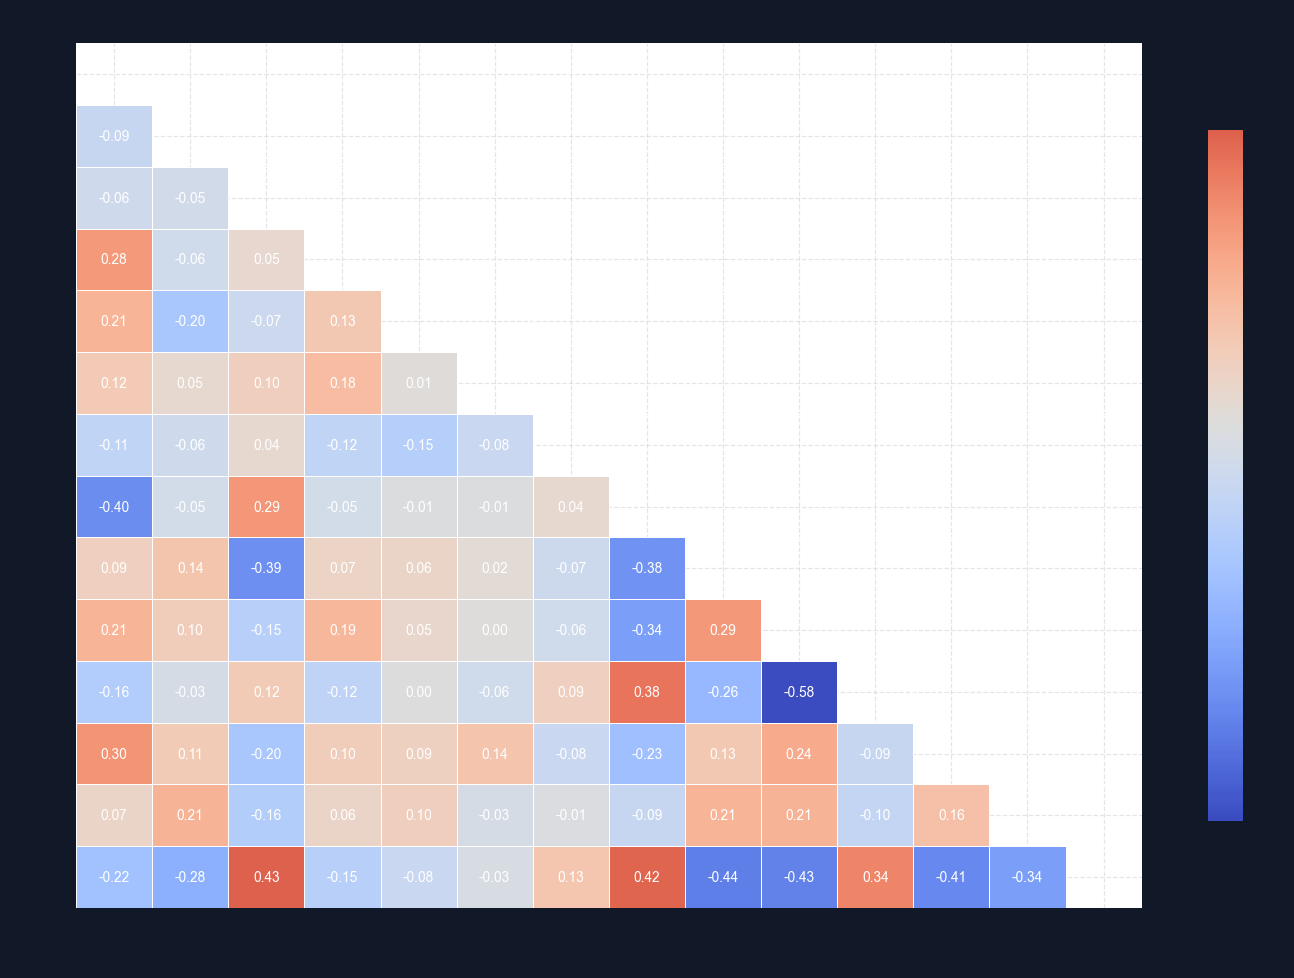

💾 Saved: feature_correlation_heatmap.png


In [49]:
# ── Correlation Heatmap ───────────────────────────────────────────────────────
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 9), facecolor=INK)
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, linewidths=0.4, linecolor="white",
    annot_kws={"size": 9, "color": "white"},
    cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Feature Correlation Matrix",
             fontsize=14, fontweight="bold", color=INK, pad=12)
plt.xticks(rotation=45, ha="right", color=INK)
plt.yticks(rotation=0, color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/feature_correlation_heatmap.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: feature_correlation_heatmap.png")

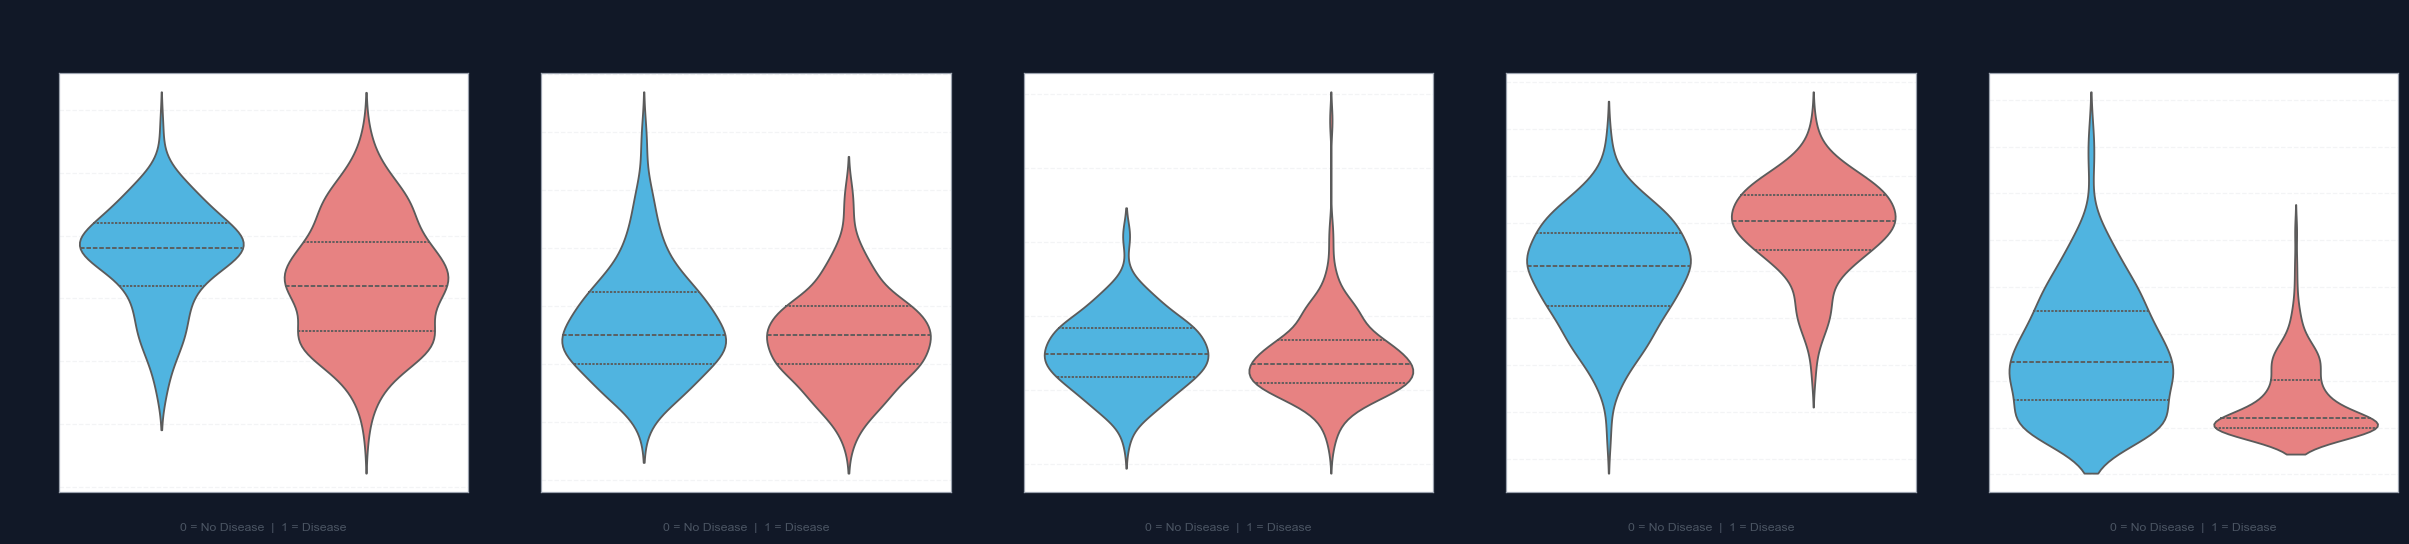

💾 Saved: EDA_violin_plots.png


In [50]:
# ── Violin Plots ──────────────────────────────────────────────────────────────
cont_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(1, 5, figsize=(22, 5), facecolor=INK)
for ax, col in zip(axes, cont_cols):
    sns.violinplot(
        data=df, x="target", y=col, hue="target", ax=ax,
        palette={0: "#38bdf8", 1: "#f87171"}, inner="quartile",
        linewidth=1.2, legend=False
    )
    ax.set_title(FEATURE_LABELS.get(col, col), fontsize=11, color=INK)
    ax.set_xlabel("0 = No Disease  |  1 = Disease", fontsize=8, color="#4b5563")
    ax.set_ylabel(col, fontsize=9)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Violin Plots — Continuous Features by Disease Status",
             fontsize=14, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/EDA_violin_plots.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: EDA_violin_plots.png")

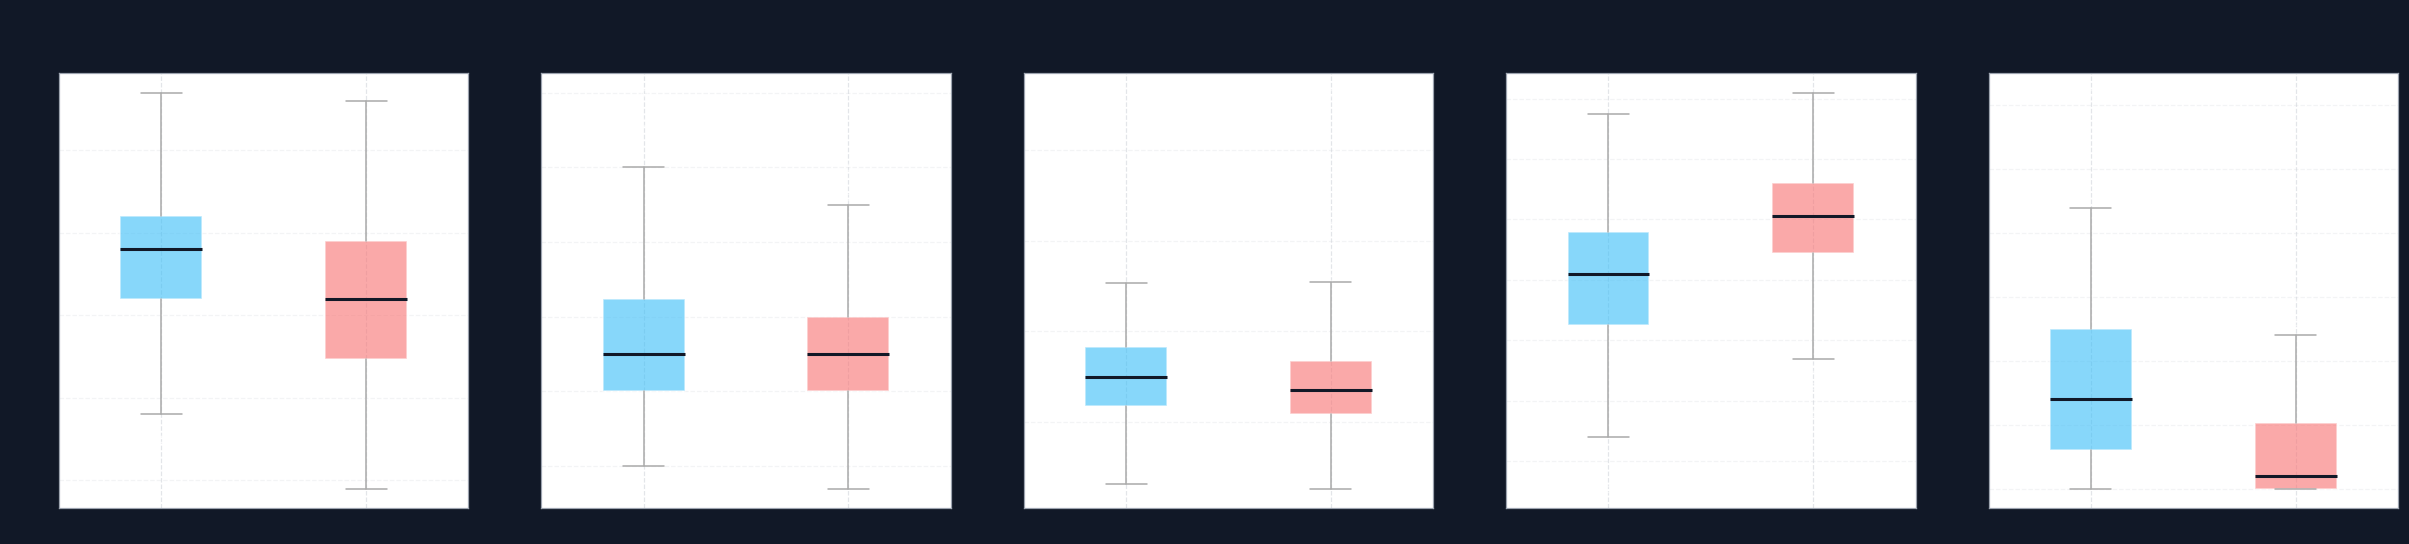

💾 Saved: outlier_detection_boxplots.png


In [51]:
# ── Boxplots / Outlier Detection ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(22, 5), facecolor=INK)
for ax, col in zip(axes, cont_cols):
    bp = ax.boxplot(
        [df[df["target"]==0][col], df[df["target"]==1][col]],
        patch_artist=True, widths=0.4,
        boxprops=dict(facecolor="#38bdf8", alpha=0.6),
        medianprops=dict(color=INK, linewidth=2),
        whiskerprops=dict(color="#aaaaaa"),
        capprops=dict(color="#aaaaaa"),
        flierprops=dict(marker="o", color="#f87171", alpha=0.5, markersize=4)
    )
    bp["boxes"][1].set_facecolor("#f87171")
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No Disease", "Disease"], color=INK, fontsize=9)
    ax.set_title(FEATURE_LABELS.get(col, col), fontsize=11, color=INK)
    ax.set_ylabel("Value", fontsize=9)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Outlier Detection — Boxplots by Disease Status",
             fontsize=14, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/outlier_detection_boxplots.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: outlier_detection_boxplots.png")

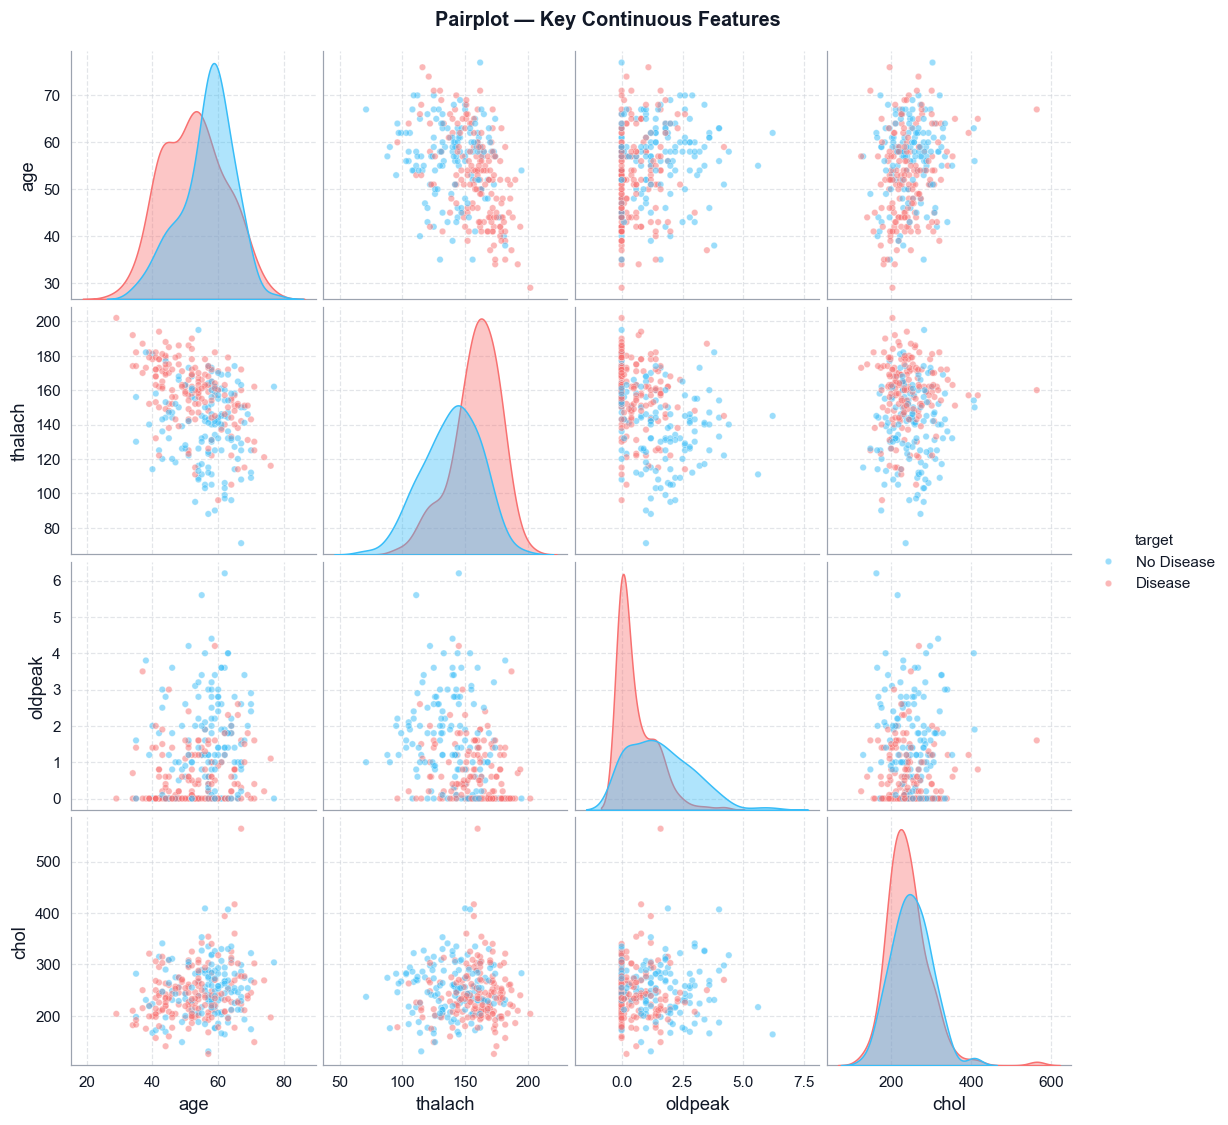

💾 Saved: EDA_pairplot_key_features.png


In [52]:
# ── Pairplot — Key Continuous Features ───────────────────────────────────────
pairplot_df = df[["age", "thalach", "oldpeak", "chol", "target"]].copy()
pairplot_df["target"] = pairplot_df["target"].map({0: "No Disease", 1: "Disease"})

g = sns.pairplot(
    pairplot_df, hue="target",
    palette={"No Disease": "#38bdf8", "Disease": "#f87171"},
    diag_kind="kde", plot_kws={"alpha": 0.5, "s": 18},
    diag_kws={"fill": True, "alpha": 0.4}
)
g.fig.set_facecolor("white")
for ax in g.axes.flatten():
    ax.tick_params(colors=INK)
    ax.xaxis.label.set_color(INK)
    ax.yaxis.label.set_color(INK)
g._legend.get_frame().set_facecolor("white")
for text in g._legend.get_texts():
    text.set_color(INK)
g.fig.suptitle("Pairplot — Key Continuous Features",
               y=1.02, fontsize=13, fontweight="bold", color=INK)
g.fig.savefig(f"{FIGURES_DIR}/EDA_pairplot_key_features.png",
              bbox_inches="tight")
plt.show()
print("💾 Saved: EDA_pairplot_key_features.png")

---
## 6. ✂️ Train / Test Split

In [53]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Train : {X_train_raw.shape}  |  Test : {X_test_raw.shape}")
print(f"Train class distribution : {dict(y_train.value_counts().rename({0:'No Disease',1:'Disease'}))}")
print(f"Test  class distribution : {dict(y_test.value_counts().rename({0:'No Disease',1:'Disease'}))}")

Train : (241, 13)  |  Test : (61, 13)
Train class distribution : {'Disease': np.int64(131), 'No Disease': np.int64(110)}
Test  class distribution : {'Disease': np.int64(33), 'No Disease': np.int64(28)}


---
## 7. 🛠️ Feature Engineering

In [54]:
# add_features() lives in heart_utils.py so the Streamlit app applies the identical transform
X_train_eng = add_features(X_train_raw)
X_test_eng  = add_features(X_test_raw)

print("Features after engineering:", X_train_eng.columns.tolist())
X_train_eng.describe().round(3)

Features after engineering: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'hr_percent', 'age_oldpeak']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hr_percent,age_oldpeak
count,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000,241.000
mean,54.195,0.676,0.983,131.315,247.631,0.137,0.535,150.826,0.299,0.995,1.423,0.759,2.336,0.910,55.909
std,9.024,0.469,1.033,16.802,53.890,0.344,0.532,22.519,0.459,1.149,0.608,1.053,0.618,0.128,66.507
min,29.000,0.000,0.000,94.000,126.000,0.000,0.000,71.000,0.000,0.000,0.000,0.000,0.000,0.464,0.000
25%,47.000,0.000,0.000,120.000,211.000,0.000,0.000,138.000,0.000,0.000,1.000,0.000,2.000,0.840,0.000
50%,55.000,1.000,1.000,130.000,241.000,0.000,1.000,154.000,0.000,0.600,1.000,0.000,2.000,0.933,33.600
75%,60.000,1.000,2.000,140.000,277.000,0.000,1.000,167.000,1.000,1.600,2.000,1.000,3.000,1.000,86.400
max,77.000,1.000,3.000,192.000,564.000,1.000,2.000,202.000,1.000,6.200,2.000,4.000,3.000,1.175,384.400


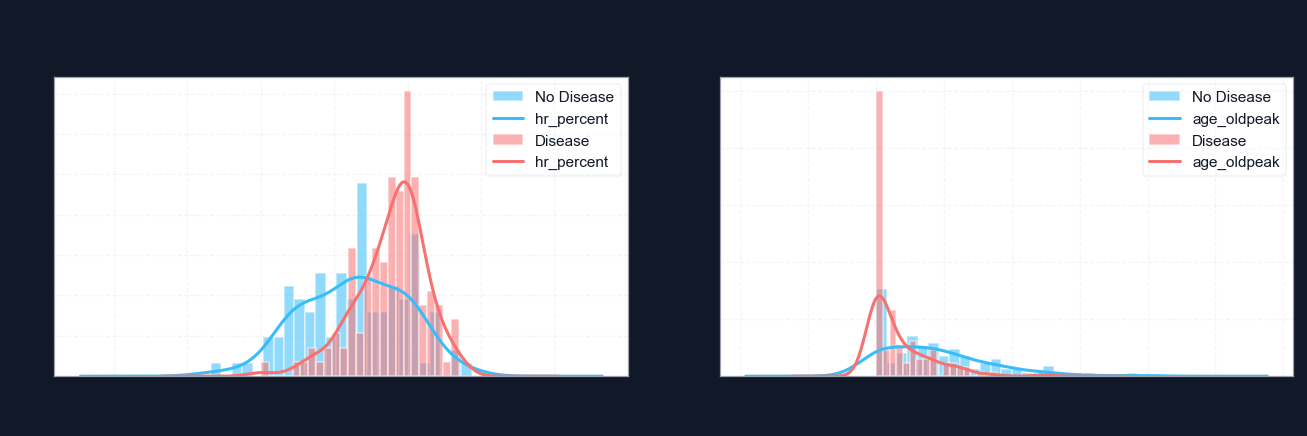

💾 Saved: engineered_features_distributions.png


In [55]:
# ── Engineered Feature Distributions ─────────────────────────────────────────
eng_feats = ["hr_percent", "age_oldpeak"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor=INK)

for ax, col in zip(axes, eng_feats):
    for label, color in PALETTE.items():
        df_tr = X_train_eng.copy()
        df_tr["target"] = y_train.values
        subset = df_tr[df_tr["target"] == label][col]
        ax.hist(subset, bins=25, alpha=0.55, color=color, density=True,
                label="No Disease" if label == 0 else "Disease")
        subset.plot.kde(ax=ax, color=color, linewidth=2)
    ax.set_title(col, fontsize=12, color=INK)
    ax.set_xlabel("Value"); ax.set_ylabel("Density")
    ax.legend(framealpha=0.3); ax.grid(alpha=0.25)

fig.suptitle("Engineered Feature Distributions by Disease Status",
             fontsize=14, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/engineered_features_distributions.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: engineered_features_distributions.png")

---
## 8. ⚖️ Class Balancing (SMOTE) & Feature Scaling

SMOTE is applied to the **training split only**; the scaler is fitted on the resampled training data and merely applied to the test set.

In [56]:
# ── SMOTE on engineering features (before scaling) ────────────────────────────
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_eng, y_train)

print("After SMOTE — class distribution:")
print(pd.Series(y_train_resampled).value_counts().rename({0:'No Disease',1:'Disease'}))
print(f"Training set size after SMOTE: {X_train_resampled.shape}")

After SMOTE — class distribution:
target
Disease       131
No Disease    131
Name: count, dtype: int64
Training set size after SMOTE: (262, 15)


In [57]:
# ── StandardScaler on continuous columns only ─────────────────────────────────
continuous_cols = CONTINUOUS_COLS

scaler = StandardScaler()

# Fit ONLY on post-SMOTE training data
X_train_resampled[continuous_cols] = scaler.fit_transform(
    X_train_resampled[continuous_cols]
)
# Transform test — never fit on test
X_test_eng[continuous_cols] = scaler.transform(
    X_test_eng[continuous_cols]
)

# Store as numpy arrays for sklearn
X_train_scaled    = X_train_resampled.values.astype(float)
X_test_scaled     = X_test_eng.values.astype(float)
all_feature_names = X_train_resampled.columns.tolist()

print("Scaler fitted.  Train shape:", X_train_scaled.shape,
      " | Test shape:", X_test_scaled.shape)

Scaler fitted.  Train shape: (262, 15)  | Test shape: (61, 15)


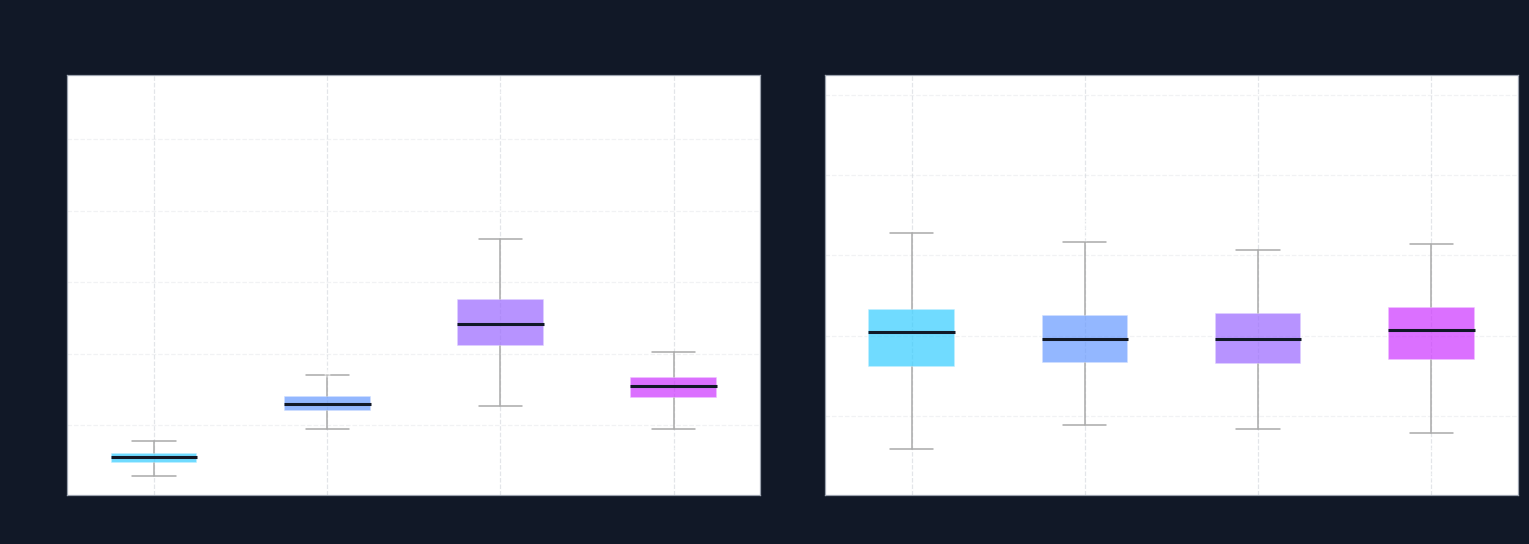

💾 Saved: feature_scaling_before_after.png


In [58]:
# ── Before vs After Scaling Comparison ───────────────────────────────────────
compare_cols = ["age", "trestbps", "chol", "thalach"]
before = X_train_raw[compare_cols]
after  = pd.DataFrame(X_train_scaled, columns=all_feature_names)[compare_cols]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=INK)
bp_kwargs = dict(patch_artist=True, widths=0.5,
                 medianprops=dict(color=INK, linewidth=2),
                 whiskerprops=dict(color="#aaaaaa"),
                 capprops=dict(color="#aaaaaa"),
                 flierprops=dict(marker="o", alpha=0.4, markersize=3))

for i, (ax, data, title) in enumerate(zip(
    axes,
    [before.values.T, after.values.T],
    ["Before Scaling (raw)", "After StandardScaler"]
)):
    colors_bp = plt.cm.cool(np.linspace(0.2, 0.8, len(compare_cols)))
    bp = ax.boxplot(list(data), **bp_kwargs)
    for patch, color in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_xticks(range(1, len(compare_cols) + 1))
    ax.set_xticklabels(compare_cols, rotation=15, color=INK)
    ax.set_title(title, fontsize=12, color=INK)
    ax.set_ylabel("Value", fontsize=10)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Feature Scaling — Before vs After",
             fontsize=14, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/feature_scaling_before_after.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: feature_scaling_before_after.png")

---
## 9. 🎯 Feature Selection — RFECV

In [59]:
print("Running RFECV (this may take ~1 minute)...")
rf_selector = RandomForestClassifier(n_estimators=60, random_state=RANDOM_STATE)
rfecv = RFECV(
    estimator=rf_selector,
    step=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc",
    min_features_to_select=5,
    n_jobs=-1
)
rfecv.fit(X_train_scaled, y_train_resampled)

selected_mask     = rfecv.support_
selected_features = np.array(all_feature_names)[selected_mask].tolist()
X_train_sel       = X_train_scaled[:, selected_mask]
X_test_sel        = X_test_scaled[:, selected_mask]

print(f"Optimal features : {rfecv.n_features_} / {len(all_feature_names)}")
print(f"Selected         : {selected_features}")

Running RFECV (this may take ~1 minute)...
Optimal features : 15 / 15
Selected         : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'hr_percent', 'age_oldpeak']


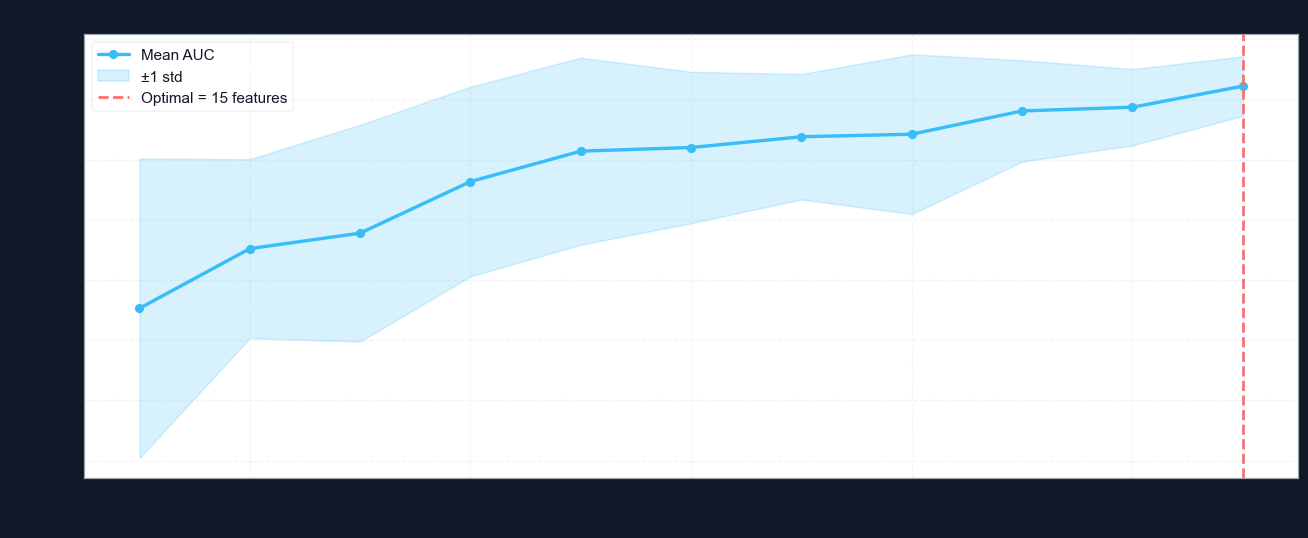

💾 Saved: RFECV_cross_validation_scores_plot.png


In [60]:
# ── RFECV Cross-Validation Score Plot ─────────────────────────────────────────
cv_res    = rfecv.cv_results_
mean_sc   = cv_res["mean_test_score"]
std_sc    = cv_res["std_test_score"]
n_range   = range(rfecv.min_features_to_select,
                  rfecv.min_features_to_select + len(mean_sc))

fig, ax = plt.subplots(figsize=(12, 5), facecolor=INK)
ax.plot(n_range, mean_sc, marker="o", color="#38bdf8", lw=2.2,
        markersize=5, label="Mean AUC")
ax.fill_between(n_range, mean_sc - std_sc, mean_sc + std_sc,
                alpha=0.2, color="#38bdf8", label="±1 std")
ax.axvline(rfecv.n_features_, color="#f87171", linestyle="--", lw=1.8,
           label=f"Optimal = {rfecv.n_features_} features")
ax.set_xlabel("Number of Features Selected", fontsize=12)
ax.set_ylabel("Cross-Validation AUC", fontsize=12)
ax.set_title("RFECV — Cross-Validation Score vs Number of Features",
             fontsize=14, fontweight="bold", color=INK)
ax.legend(framealpha=0.3)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/RFECV_cross_validation_scores_plot.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: RFECV_cross_validation_scores_plot.png")

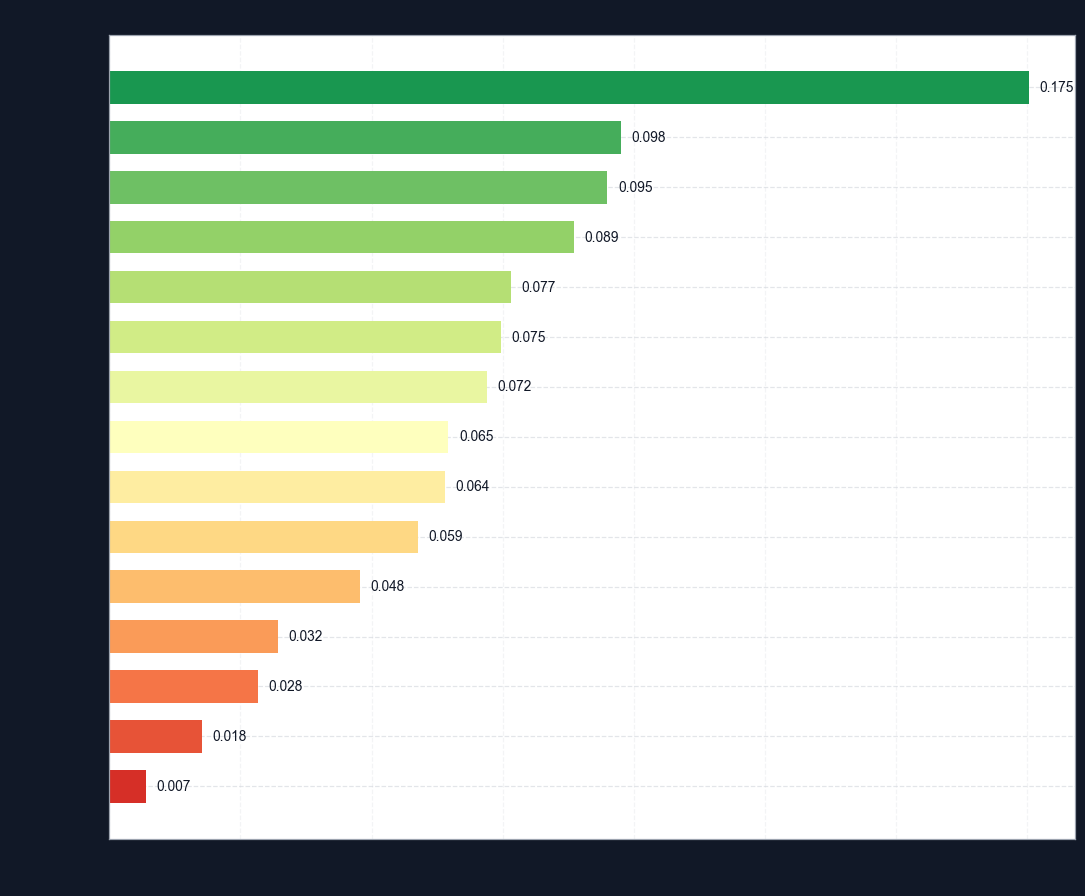

💾 Saved: feature_importance_bar_chart.png


In [61]:
# ── Feature Importance Bar Chart (RF on selected features) ────────────────────
rf_imp = RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE)
rf_imp.fit(X_train_sel, y_train_resampled)
imp_series = pd.Series(rf_imp.feature_importances_,
                       index=selected_features).sort_values(ascending=True)

colors_imp = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(imp_series)))
fig, ax = plt.subplots(figsize=(10, max(4, len(imp_series) * 0.55)),
                       facecolor=INK)
bars = ax.barh(imp_series.index, imp_series.values, color=colors_imp,
               edgecolor="none", height=0.65)
for bar, val in zip(bars, imp_series.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Mean Decrease in Impurity (Gini)", fontsize=11)
ax.set_title("Feature Importance — Random Forest (Selected Features)",
             fontsize=13, fontweight="bold", color=INK)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/feature_importance_bar_chart.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: feature_importance_bar_chart.png")

---
## 10. 🤖 Model Development & Hyperparameter Tuning

In [62]:
# ── Model Configuration ───────────────────────────────────────────────────────
# NOTE: X_train_sel / X_test_sel are already imputed numpy arrays (no NaNs),
# but a SimpleImputer is kept inside each pipeline for robustness.

model_configs = {
    "Logistic Regression": {
        "pipeline": Pipeline([
            ("imputer",    SimpleImputer(strategy="mean")),
            ("classifier", LogisticRegression(random_state=RANDOM_STATE,
                                              max_iter=1000))
        ]),
        "params": {
            "classifier__C":       [0.01, 0.1, 1, 10],
            "classifier__penalty": ["l1", "l2"],
            "classifier__solver":  ["liblinear"]
        }
    },
    "Random Forest": {
        "pipeline": Pipeline([
            ("imputer",    SimpleImputer(strategy="mean")),
            ("classifier", RandomForestClassifier(random_state=RANDOM_STATE))
        ]),
        "params": {
            "classifier__n_estimators":      [80, 150],
            "classifier__max_depth":         [5, 10, None],
            "classifier__min_samples_split": [2, 5]
        }
    },
    "XGBoost": {
        "pipeline": Pipeline([
            ("imputer",    SimpleImputer(strategy="mean")),
            # use_label_encoder removed in XGBoost ≥ 1.6
            ("classifier", XGBClassifier(random_state=RANDOM_STATE,
                                          eval_metric="logloss",
                                          verbosity=0))
        ]),
        "params": {
            "classifier__n_estimators":  [80, 150],
            "classifier__learning_rate": [0.05, 0.1, 0.2],
            "classifier__max_depth":     [3, 5, 7],
            "classifier__subsample":     [0.8, 1.0]
        }
    },
    "SVM": {
        "pipeline": Pipeline([
            ("imputer",    SimpleImputer(strategy="mean")),
            ("classifier", SVC(random_state=RANDOM_STATE, probability=True))
        ]),
        "params": {
            "classifier__C":      [0.1, 1, 10],
            "classifier__gamma":  ["scale", "auto"],
            "classifier__kernel": ["linear", "rbf"]
        }
    }
}

best_estimators = {}

for name, cfg in model_configs.items():
    print(f"--- Tuning {name} ---")
    grid = GridSearchCV(
        cfg["pipeline"], cfg["params"],
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
        scoring="roc_auc", n_jobs=-1, verbose=0
    )
    grid.fit(X_train_sel, y_train_resampled)
    best_estimators[name] = grid.best_estimator_
    print(f"  CV AUC      : {grid.best_score_:.4f}")
    print(f"  Best params : {grid.best_params_}")

print("\n✅ All models tuned.")

--- Tuning Logistic Regression ---
  CV AUC      : 0.9121
  Best params : {'classifier__C': 10, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
--- Tuning Random Forest ---
  CV AUC      : 0.9103
  Best params : {'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 150}
--- Tuning XGBoost ---
  CV AUC      : 0.9169
  Best params : {'classifier__learning_rate': 0.2, 'classifier__max_depth': 5, 'classifier__n_estimators': 150, 'classifier__subsample': 0.8}
--- Tuning SVM ---
  CV AUC      : 0.9134
  Best params : {'classifier__C': 1, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}

✅ All models tuned.


---
## 11. 🏗️ Stacking Classifier

In [63]:
base_learners = [
    ("rf",  best_estimators["Random Forest"]),
    ("xgb", best_estimators["XGBoost"]),
    ("svm", best_estimators["SVM"])
]
meta_learner = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)

stacking_clf = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba",
    n_jobs=-1
)
stacking_clf.fit(X_train_sel, y_train_resampled)
best_estimators["Stacking"] = stacking_clf
print("✅ Stacking Classifier fitted successfully.")

✅ Stacking Classifier fitted successfully.


---
## 12. 🧪 Model Evaluation on Test Set

In [64]:
# ── Metrics Table ─────────────────────────────────────────────────────────────
results = []
for name, model in best_estimators.items():
    y_pred  = model.predict(X_test_sel)
    y_proba = model.predict_proba(X_test_sel)[:, 1]
    results.append({
        "Model":     name,
        "Accuracy":  round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall":    round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score":  round(f1_score(y_test, y_pred, zero_division=0), 4),
        "AUC-ROC":   round(roc_auc_score(y_test, y_proba), 4),
        "MCC":       round(matthews_corrcoef(y_test, y_pred), 4)
    })

results_df = pd.DataFrame(results).set_index("Model")

print("=" * 70)
print("MODEL PERFORMANCE — HELD-OUT TEST SET")
print("=" * 70)
print(results_df.to_string())

results_df.style \
    .highlight_max(color="#bbf7d0") \
    .format(precision=4) \
    .set_caption("Test-Set Metrics — All Models")

MODEL PERFORMANCE — HELD-OUT TEST SET
                     Accuracy  Precision  Recall  F1-Score  AUC-ROC     MCC
Model                                                                      
Logistic Regression    0.7541     0.7812  0.7576    0.7692   0.8485  0.5065
Random Forest          0.7377     0.7742  0.7273    0.7500   0.8593  0.4757
XGBoost                0.6885     0.7188  0.6970    0.7077   0.8214  0.3747
SVM                    0.7705     0.7879  0.7879    0.7879   0.8485  0.5379
Stacking               0.7213     0.7667  0.6970    0.7302   0.8485  0.4455


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,MCC
Model,,,,,,
Logistic Regression,0.7541,0.7812,0.7576,0.7692,0.8485,0.5065
Random Forest,0.7377,0.7742,0.7273,0.7500,0.8593,0.4757
XGBoost,0.6885,0.7188,0.6970,0.7077,0.8214,0.3747
SVM,0.7705,0.7879,0.7879,0.7879,0.8485,0.5379
Stacking,0.7213,0.7667,0.6970,0.7302,0.8485,0.4455


In [65]:
# ── CV vs Test AUC Gap ────────────────────────────────────────────────────────
print("5-Fold CV AUC (training) vs Test AUC")
print("-" * 60)
for name, model in best_estimators.items():
    cv_auc  = cross_val_score(model, X_train_sel, y_train_resampled,
                              cv=StratifiedKFold(5, shuffle=True,
                                                 random_state=RANDOM_STATE),
                              scoring="roc_auc", n_jobs=-1)
    test_auc = results_df.loc[name, "AUC-ROC"]
    gap      = cv_auc.mean() - test_auc
    print(f"  {name:22s}: CV={cv_auc.mean():.4f}±{cv_auc.std():.4f}  "
          f"Test={test_auc:.4f}  Gap={gap:+.4f}")

5-Fold CV AUC (training) vs Test AUC
------------------------------------------------------------
  Logistic Regression   : CV=0.9121±0.0259  Test=0.8485  Gap=+0.0636
  Random Forest         : CV=0.9103±0.0194  Test=0.8593  Gap=+0.0510
  XGBoost               : CV=0.9169±0.0162  Test=0.8214  Gap=+0.0955
  SVM                   : CV=0.9134±0.0278  Test=0.8485  Gap=+0.0649
  Stacking              : CV=0.9209±0.0078  Test=0.8485  Gap=+0.0724


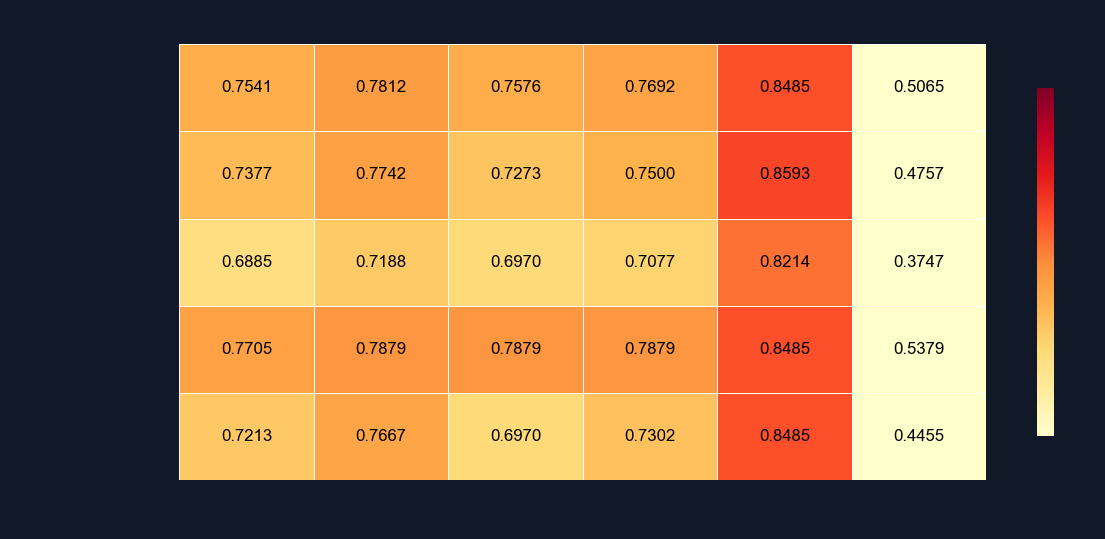

💾 Saved: heatmap_model_performance.png


In [66]:
# ── Heatmap — Model Performance ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5), facecolor=INK)
sns.heatmap(
    results_df, annot=True, fmt=".4f", cmap="YlOrRd",
    vmin=0.6, vmax=1.0,
    linewidths=0.5, linecolor="white",
    annot_kws={"size": 11, "color": "black"},
    cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Heatmap — Model Performance Metrics on Test Set",
             fontsize=14, fontweight="bold", color=INK, pad=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, color=INK)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right", color=INK)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/heatmap_model_performance.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: heatmap_model_performance.png")

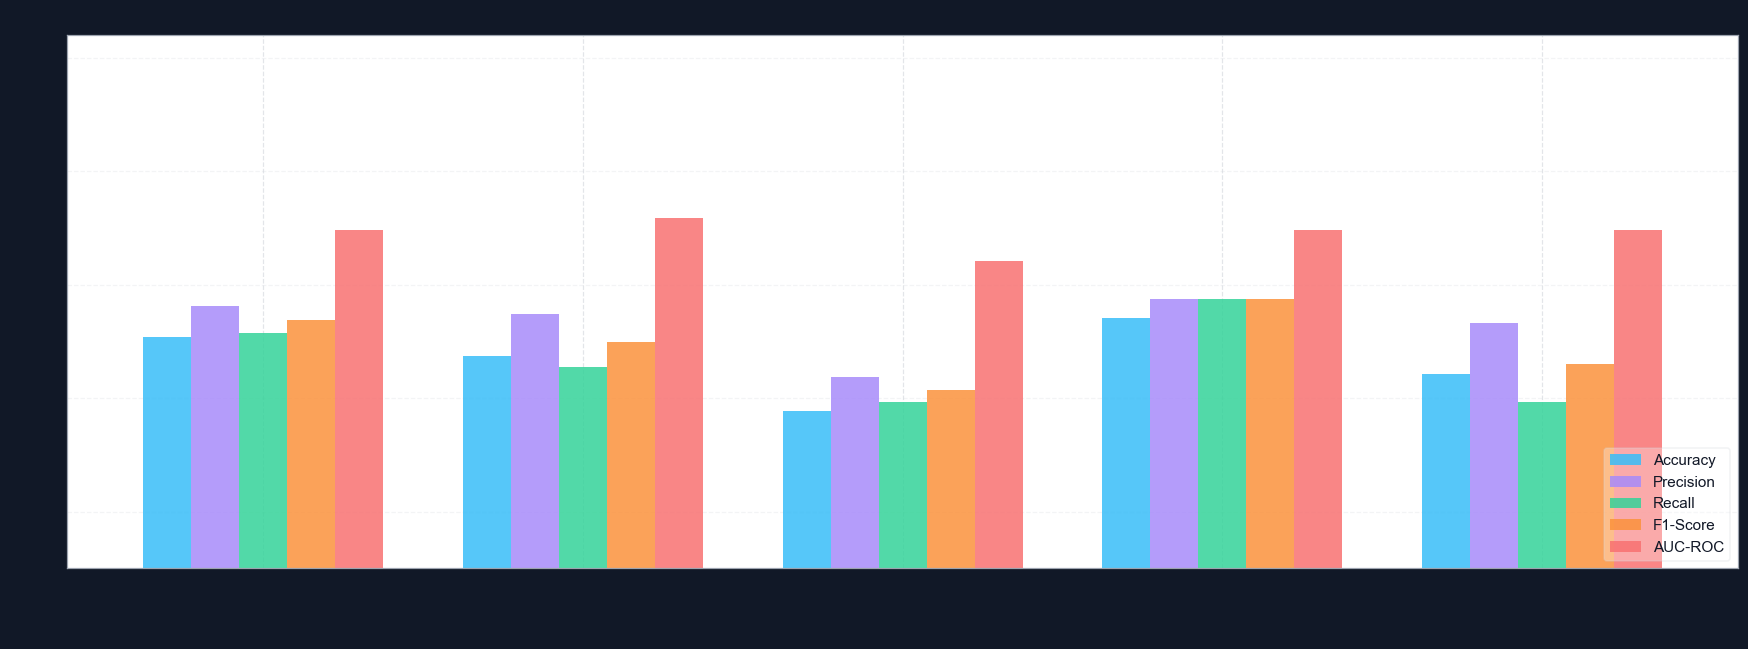

💾 Saved: model_comparison_bar_chart.png


In [67]:
# ── Model Comparison Bar Chart ─────────────────────────────────────────────────
metrics  = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
x        = np.arange(len(results_df))
width    = 0.15
colors_m = ["#38bdf8", "#a78bfa", "#34d399", "#fb923c", "#f87171"]

fig, ax = plt.subplots(figsize=(16, 6), facecolor=INK)

for i, (metric, color) in enumerate(zip(metrics, colors_m)):
    bars = ax.bar(x + i * width, results_df[metric], width,
                  label=metric, color=color, alpha=0.85, edgecolor="none")

ax.set_xticks(x + width * 2)
ax.set_xticklabels(results_df.index, rotation=20, ha="right", color=INK)
ax.set_ylim(0.55, 1.02)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Model Comparison — All Metrics on Test Set",
             fontsize=14, fontweight="bold", color=INK)
ax.legend(loc="lower right", framealpha=0.3)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/model_comparison_bar_chart.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: model_comparison_bar_chart.png")

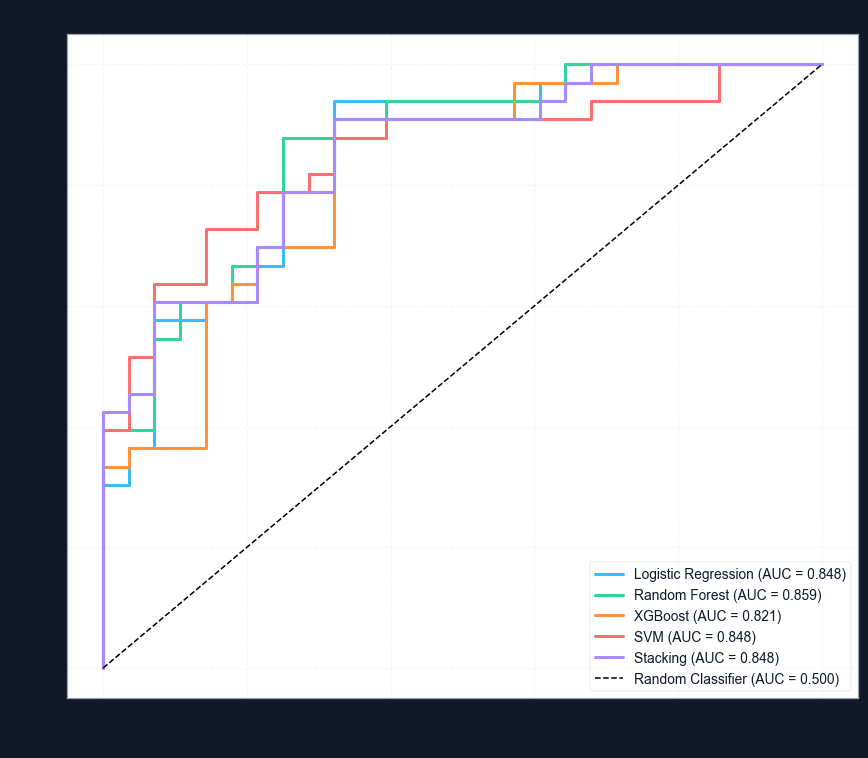

💾 Saved: ROC_curves_all_models.png


In [68]:
# ── ROC Curves for All Models ─────────────────────────────────────────────────
roc_colors = ["#38bdf8", "#34d399", "#fb923c", "#f87171", "#a78bfa"]

fig, ax = plt.subplots(figsize=(8, 7), facecolor=INK)

for (name, model), color in zip(best_estimators.items(), roc_colors):
    y_proba = model.predict_proba(X_test_sel)[:, 1]
    auc     = roc_auc_score(y_test, y_proba)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random Classifier (AUC = 0.500)")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curves for All Models — Held-Out Test Set",
             fontsize=14, fontweight="bold", color=INK)
ax.legend(loc="lower right", fontsize=9, framealpha=0.3)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/ROC_curves_all_models.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: ROC_curves_all_models.png")

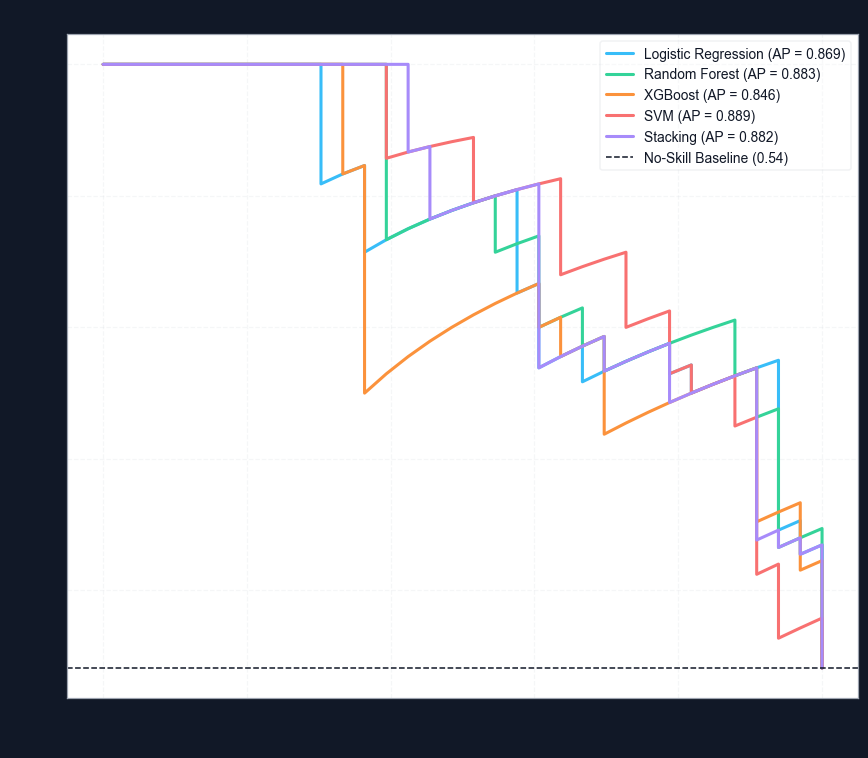

💾 Saved: precision_recall_curves_all_models.png


In [69]:
# ── Precision-Recall Curves ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7), facecolor=INK)

for (name, model), color in zip(best_estimators.items(), roc_colors):
    y_proba = model.predict_proba(X_test_sel)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    ax.plot(rec, prec, color=color, lw=2, label=f"{name} (AP = {ap:.3f})")

baseline = y_test.mean()
ax.axhline(baseline, color=INK, linestyle="--", lw=1,
           label=f"No-Skill Baseline ({baseline:.2f})")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves for All Models",
             fontsize=14, fontweight="bold", color=INK)
ax.legend(loc="upper right", fontsize=9, framealpha=0.3)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/precision_recall_curves_all_models.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: precision_recall_curves_all_models.png")

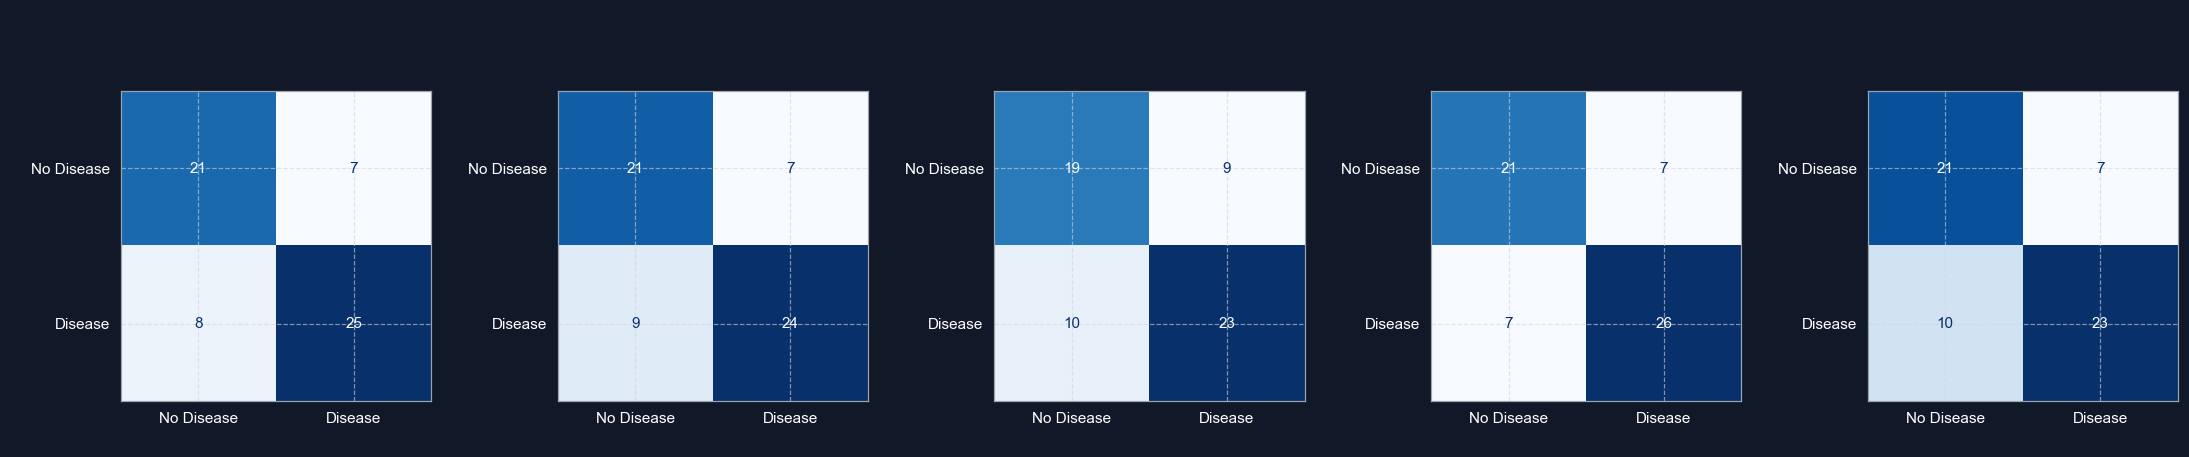

💾 Saved: confusion_matrices_all_models.png


In [70]:
# ── Confusion Matrices ─────────────────────────────────────────────────────────
n_models = len(best_estimators)
fig, axes = plt.subplots(1, n_models,
                         figsize=(4 * n_models, 4),
                         facecolor=INK)

for ax, (name, model) in zip(axes, best_estimators.items()):
    y_pred = model.predict(X_test_sel)
    disp = ConfusionMatrixDisplay(
        confusion_matrix(y_test, y_pred),
        display_labels=["No Disease", "Disease"]
    )
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10, fontweight="bold", color=INK)
    ax.set_xlabel("Predicted Label", color=INK, fontsize=9)
    ax.set_ylabel("True Label", color=INK, fontsize=9)
    ax.tick_params(colors="white")

fig.suptitle("Confusion Matrices — Held-Out Test Set",
             fontsize=14, fontweight="bold", color=INK, y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/confusion_matrices_all_models.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: confusion_matrices_all_models.png")

---
## 13. 🔬 Explainability with SHAP

SHAP (SHapley Additive exPlanations) attributes model predictions to individual features using game-theory Shapley values.  
We use `TreeExplainer` on the **XGBoost classifier** extracted from its pipeline.

In [71]:
# ── Extract the fitted classifier and imputed test data from the XGBoost pipeline
# ─────────────────────────────────────────────────────────────────────────────
# IMPORTANT: shap.TreeExplainer requires the raw XGBoost model, NOT the full
# sklearn Pipeline. We extract the classifier and imputer steps separately.
xgb_pipeline = best_estimators["XGBoost"]
xgb_imputer  = xgb_pipeline.named_steps["imputer"]
xgb_clf      = xgb_pipeline.named_steps["classifier"]

# Apply the pipeline's imputer to the test set (data is already scaled; this
# step handles any residual NaNs)
X_test_imputed = xgb_imputer.transform(X_test_sel)   # shape: (n_test, n_features)
X_train_imputed = xgb_imputer.transform(X_train_sel)  # needed for LIME background

# ── Fit SHAP TreeExplainer ────────────────────────────────────────────────────
shap_explainer = shap.TreeExplainer(xgb_clf)
shap_values    = shap_explainer.shap_values(X_test_imputed)  # returns ndarray (n, n_feat)
expected_value = float(shap_explainer.expected_value)         # scalar baseline (log-odds)

print("SHAP values shape  :", shap_values.shape)
print("Expected value     :", round(expected_value, 4))
print("Features used      :", selected_features)

SHAP values shape  : (61, 15)
Expected value     : -0.1283
Features used      : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'hr_percent', 'age_oldpeak']


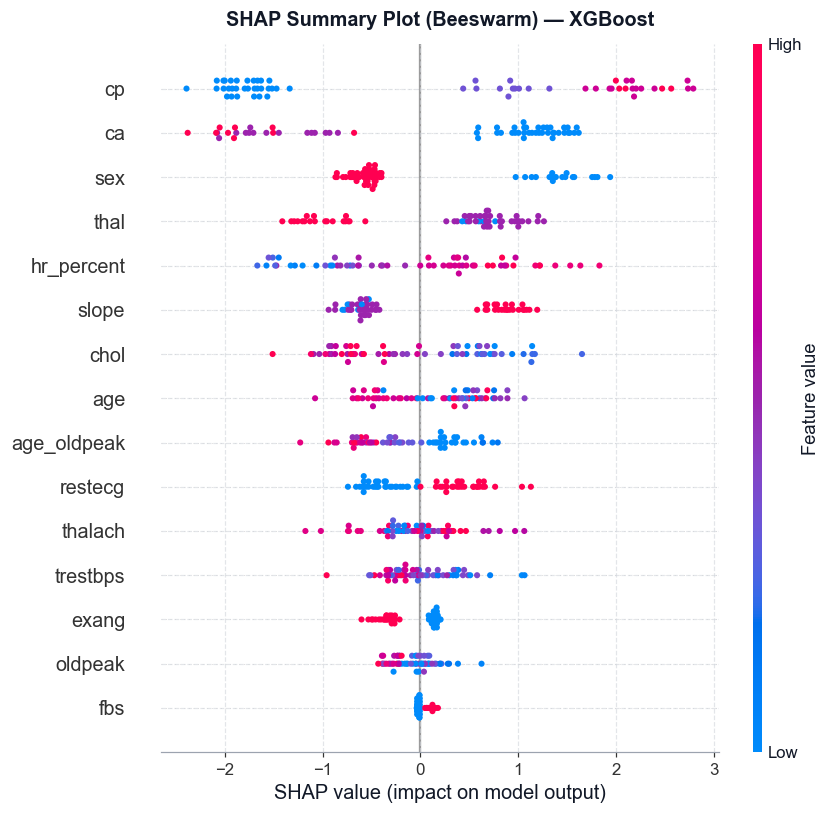

💾 Saved: SHAP_summary_beeswarm_plot.png


In [72]:
# ── SHAP Beeswarm Summary Plot ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6), facecolor=INK)
# shap.summary_plot manages its own axes; use plt style override

shap.summary_plot(
    shap_values,
    X_test_imputed,
    feature_names=selected_features,
    plot_type="dot",
    max_display=len(selected_features),
    show=False
)
plt.title("SHAP Summary Plot (Beeswarm) — XGBoost",
          fontsize=13, fontweight="bold", color=INK, pad=12)
plt.gcf().set_facecolor("white")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/SHAP_summary_beeswarm_plot.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: SHAP_summary_beeswarm_plot.png")

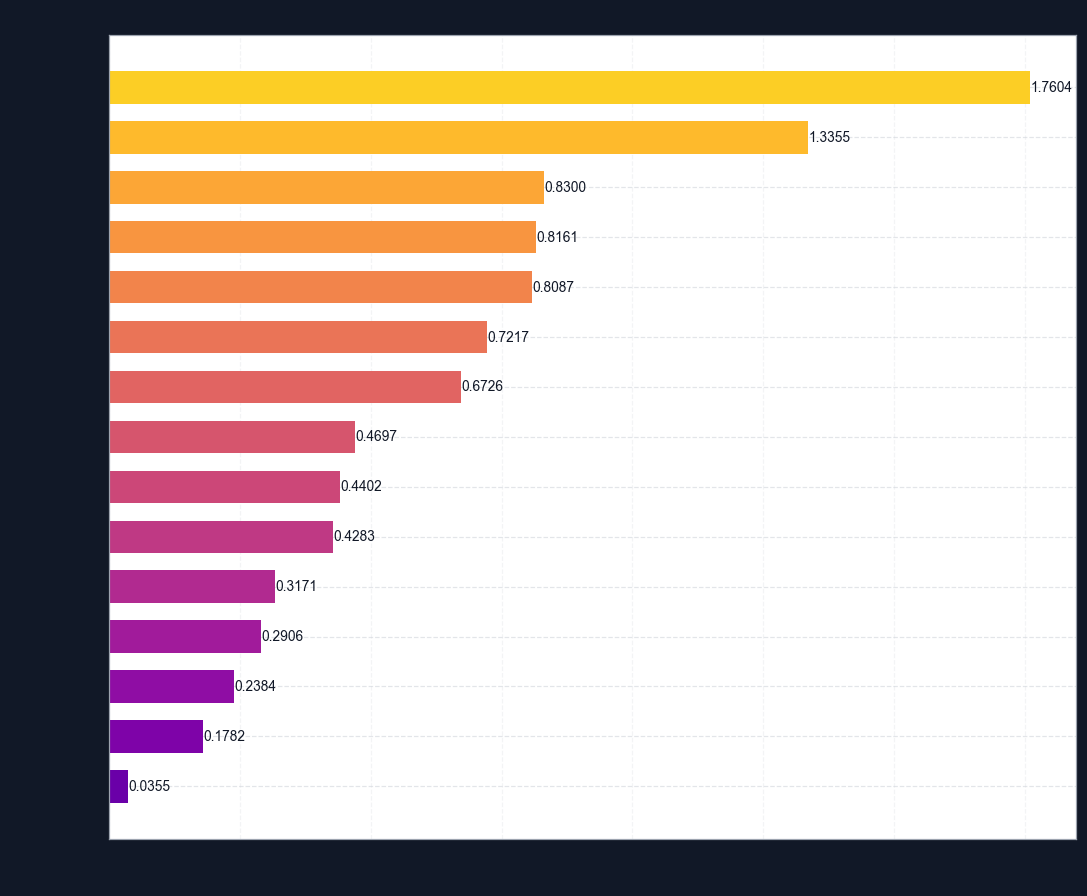

💾 Saved: SHAP_global_feature_importance_bar_plot.png


In [73]:
# ── SHAP Bar Plot (Global Mean |SHAP|) ────────────────────────────────────────
mean_shap = np.abs(shap_values).mean(axis=0)
shap_df   = pd.DataFrame({"Feature":    selected_features,
                           "Mean |SHAP|": mean_shap}) \
              .sort_values("Mean |SHAP|", ascending=True)

colors_sh = plt.cm.plasma(np.linspace(0.2, 0.9, len(shap_df)))
fig, ax = plt.subplots(figsize=(10, max(4, len(shap_df) * 0.55)), facecolor=INK)
bars = ax.barh(shap_df["Feature"], shap_df["Mean |SHAP|"],
               color=colors_sh, edgecolor="none", height=0.65)
for bar, val in zip(bars, shap_df["Mean |SHAP|"]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Mean |SHAP Value|  (impact on model output)", fontsize=11)
ax.set_title("SHAP Global Feature Importance — XGBoost",
             fontsize=13, fontweight="bold", color=INK)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/SHAP_global_feature_importance_bar_plot.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: SHAP_global_feature_importance_bar_plot.png")

Top SHAP feature: cp


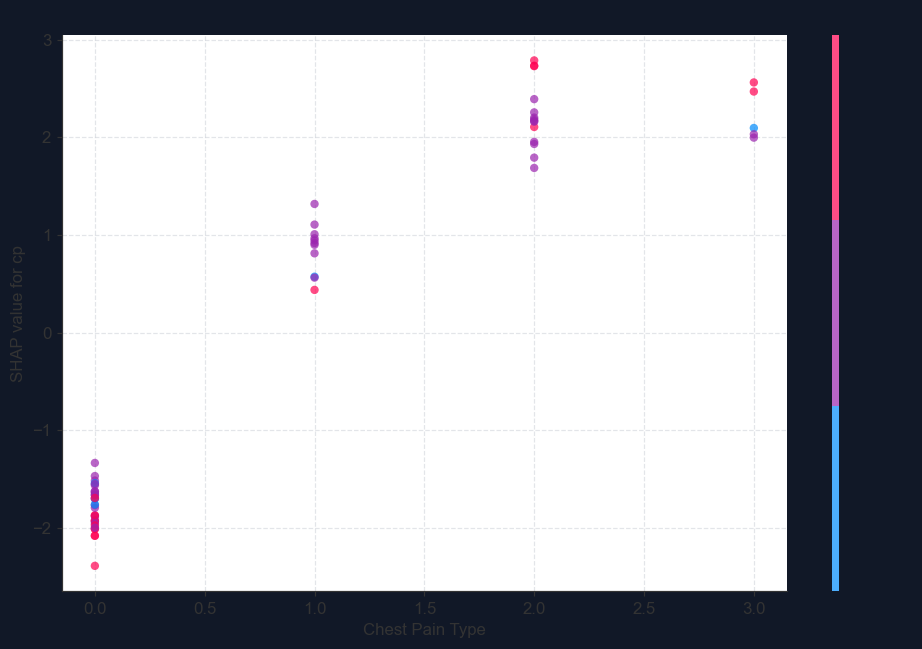

💾 Saved: SHAP_dependence_plot.png


In [74]:
# ── SHAP Dependence Plot — Top Feature ────────────────────────────────────────
top_feature_idx  = int(np.abs(shap_values).mean(axis=0).argmax())
top_feature_name = selected_features[top_feature_idx]
print(f"Top SHAP feature: {top_feature_name}")

fig, ax = plt.subplots(figsize=(9, 6), facecolor=INK)
shap.dependence_plot(
    top_feature_name,
    shap_values,
    X_test_imputed,
    feature_names=selected_features,
    ax=ax,
    show=False,
    dot_size=30,
    alpha=0.7
)
ax.set_title(f"SHAP Dependence Plot — {top_feature_name}",
             fontsize=13, fontweight="bold", color=INK)
ax.set_xlabel(FEATURE_LABELS.get(top_feature_name, top_feature_name), fontsize=11)
ax.set_ylabel(f"SHAP value for {top_feature_name}", fontsize=11)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/SHAP_dependence_plot.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: SHAP_dependence_plot.png")

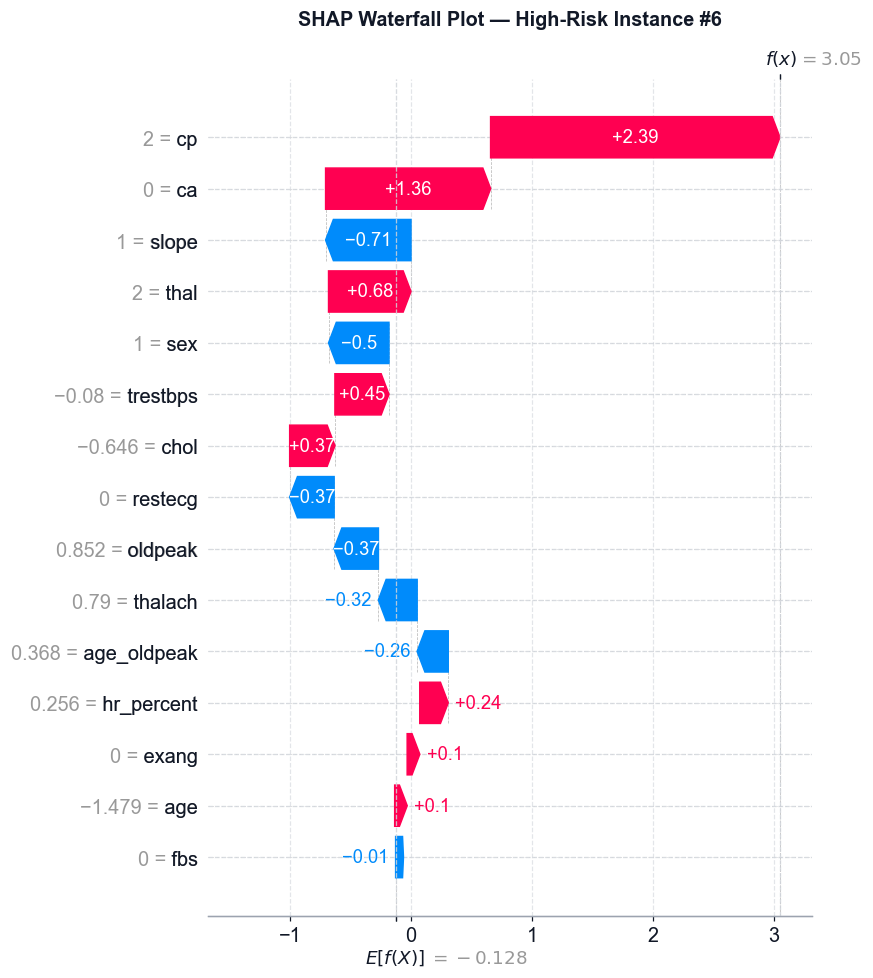

💾 Saved: SHAP_waterfall_single_prediction.png


In [75]:
# ── SHAP Waterfall — Single High-Risk Prediction ──────────────────────────────
# Find a true-positive (correctly predicted disease) instance
y_pred_xgb = xgb_pipeline.predict(X_test_sel)
tp_idx = np.where((y_pred_xgb == 1) & (y_test.values == 1))[0]
instance_idx = int(tp_idx[0]) if len(tp_idx) > 0 else 0

exp_obj = shap.Explanation(
    values        = shap_values[instance_idx],
    base_values   = expected_value,
    data          = X_test_imputed[instance_idx],
    feature_names = selected_features
)

fig, ax = plt.subplots(figsize=(10, 6), facecolor=INK)
shap.plots.waterfall(exp_obj, max_display=len(selected_features), show=False)
plt.title(f"SHAP Waterfall Plot — High-Risk Instance #{instance_idx}",
          fontsize=13, fontweight="bold", color=INK, pad=15)
plt.gcf().set_facecolor("white")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/SHAP_waterfall_single_prediction.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: SHAP_waterfall_single_prediction.png")

---
## 14. 🔍 LIME — Local Explanations

LIME (Local Interpretable Model-agnostic Explanations) fits a simple linear surrogate model in the neighbourhood of each prediction, attributing a signed weight to each feature for that specific instance.

In [76]:
# ── Create LIME Explainer ─────────────────────────────────────────────────────
# Pass the post-imputation training data as background.
# We use the XGBoost pipeline's predict_proba — LIME calls the full pipeline
# so predictions are consistent with the trained model.

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data        = X_train_imputed,   # numpy array, no NaNs
    feature_names        = selected_features,
    class_names          = ["No Disease", "Disease"],
    mode                 = "classification",
    discretize_continuous= True,              # bin continuous features for LIME
    random_state         = RANDOM_STATE
)
print("✅ LIME explainer created.")
print(f"   Background data shape : {X_train_imputed.shape}")
print(f"   Features              : {selected_features}")

✅ LIME explainer created.
   Background data shape : (262, 15)
   Features              : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'hr_percent', 'age_oldpeak']


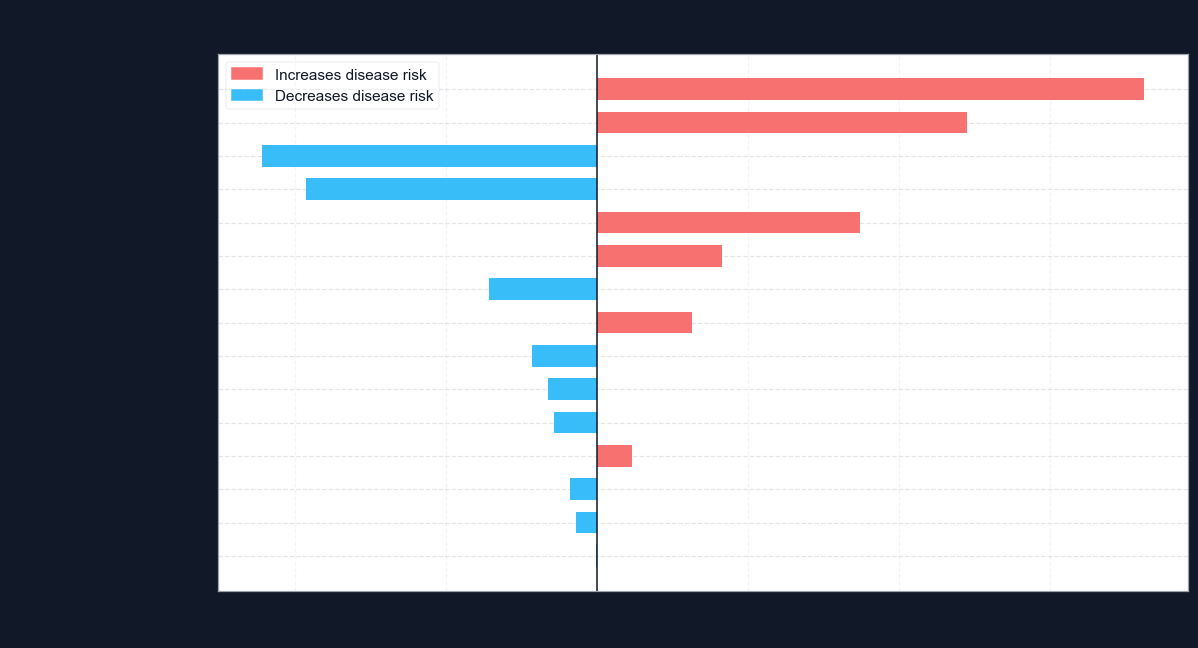

💾 Saved: LIME_local_explanation_high_risk.png

LIME feature contributions (high-risk instance):
  ca <= 0.00                              : +0.3622  (↑ increases risk)
  thal <= 2.00                            : +0.2451  (↑ increases risk)
  0.00 < sex <= 1.00                      : -0.2221  (↓ decreases risk)
  slope <= 1.00                           : -0.1928  (↓ decreases risk)
  0.50 < cp <= 2.00                       : +0.1740  (↑ increases risk)
  0.18 < hr_percent <= 0.73               : +0.0826  (↑ increases risk)
  restecg <= 0.00                         : -0.0715  (↓ decreases risk)
  exang <= 0.00                           : +0.0626  (↑ increases risk)
  -0.68 < trestbps <= -0.08               : -0.0431  (↓ decreases risk)
  thalach > 0.70                          : -0.0324  (↓ decreases risk)
  fbs <= 0.00                             : -0.0286  (↓ decreases risk)
  -0.70 < chol <= -0.09                   : +0.0233  (↑ increases risk)
  oldpeak > 0.50                        

In [77]:
# ── LIME — High-Risk Instance (True Positive) ─────────────────────────────────
# Use the same true-positive instance found for SHAP
lime_instance = X_test_imputed[instance_idx]   # 1-D numpy array

lime_exp_high = lime_explainer.explain_instance(
    data_row      = lime_instance,
    predict_fn    = xgb_pipeline.predict_proba,  # full pipeline → consistent probabilities
    num_features  = len(selected_features),
    top_labels    = 1,
    num_samples   = 3000
)

# Extract contributions for class 1 (Disease)
lime_list_high = lime_exp_high.as_list(label=1)
feat_names_h   = [e[0] for e in lime_list_high]
feat_weights_h = [e[1] for e in lime_list_high]
bar_colors_h   = ["#f87171" if w > 0 else "#38bdf8" for w in feat_weights_h]

fig, ax = plt.subplots(figsize=(11, 6), facecolor=INK)
ax.barh(feat_names_h[::-1], feat_weights_h[::-1],
        color=bar_colors_h[::-1], edgecolor="none", height=0.65)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel("LIME Feature Weight (impact on Disease probability)", fontsize=11)
ax.set_title(
    f"LIME Local Explanation — High-Risk Instance #{instance_idx}\n"
    f"True Label: Disease  |  Predicted: Disease  |  "
    f"P(Disease) = {xgb_pipeline.predict_proba(X_test_sel[[instance_idx]])[0,1]:.3f}",
    fontsize=12, fontweight="bold", color=INK
)
red_p   = mpatches.Patch(color="#f87171", label="Increases disease risk")
blue_p  = mpatches.Patch(color="#38bdf8", label="Decreases disease risk")
ax.legend(handles=[red_p, blue_p], framealpha=0.3, fontsize=10)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/LIME_local_explanation_high_risk.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: LIME_local_explanation_high_risk.png")

print("\nLIME feature contributions (high-risk instance):")
for feat, weight in sorted(lime_list_high, key=lambda x: abs(x[1]), reverse=True):
    direction = "↑ increases risk" if weight > 0 else "↓ decreases risk"
    print(f"  {feat:40s}: {weight:+.4f}  ({direction})")

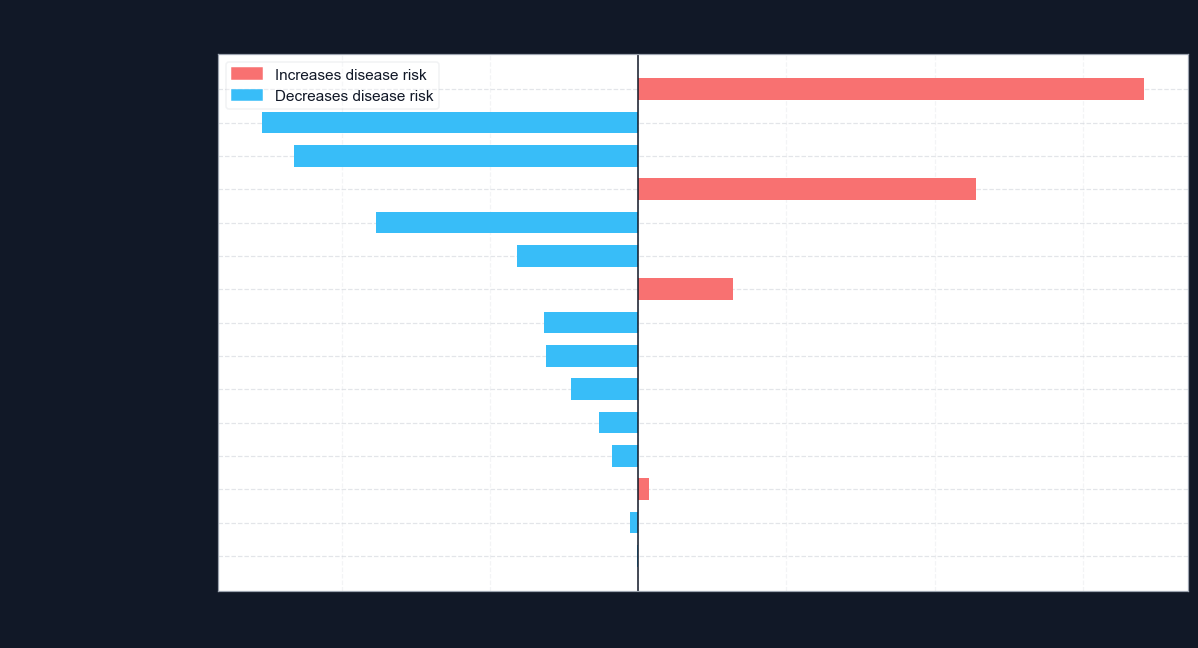

💾 Saved: LIME_local_explanation_low_risk.png


In [78]:
# ── LIME — Low-Risk Instance (True Negative) ──────────────────────────────────
tn_idx_arr   = np.where((y_pred_xgb == 0) & (y_test.values == 0))[0]
low_risk_idx = int(tn_idx_arr[0]) if len(tn_idx_arr) > 0 else 5

lime_exp_low = lime_explainer.explain_instance(
    data_row     = X_test_imputed[low_risk_idx],
    predict_fn   = xgb_pipeline.predict_proba,
    num_features = len(selected_features),
    top_labels   = 2,   # always explain both classes so label=1 is present
    num_samples  = 3000
)

lime_list_low   = lime_exp_low.as_list(label=1)
feat_names_l    = [e[0] for e in lime_list_low]
feat_weights_l  = [e[1] for e in lime_list_low]
bar_colors_l    = ["#f87171" if w > 0 else "#38bdf8" for w in feat_weights_l]

fig, ax = plt.subplots(figsize=(11, 6), facecolor=INK)
ax.barh(feat_names_l[::-1], feat_weights_l[::-1],
        color=bar_colors_l[::-1], edgecolor="none", height=0.65)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel("LIME Feature Weight (impact on Disease probability)", fontsize=11)
ax.set_title(
    f"LIME Local Explanation — Low-Risk Instance #{low_risk_idx}\n"
    f"True Label: No Disease  |  Predicted: No Disease  |  "
    f"P(Disease) = {xgb_pipeline.predict_proba(X_test_sel[[low_risk_idx]])[0,1]:.3f}",
    fontsize=12, fontweight="bold", color=INK
)
ax.legend(handles=[red_p, blue_p], framealpha=0.3, fontsize=10)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/LIME_local_explanation_low_risk.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: LIME_local_explanation_low_risk.png")

---
## 15. 💡 Actionable Explanations

SHAP contributions are translated into clinical next steps. Recommendations are issued **only for factors that push the prediction towards disease**; protective factors are listed without an action.

In [79]:
# ── Clinical Action Map (ACTION_MAP is defined in heart_utils.py) ─────────────
def generate_actionable_explanation(shap_vals, feature_names, instance_data,
                                     model_pipeline, threshold=0.03):
    """Return a clinical risk report based on SHAP contributions."""
    pred  = model_pipeline.predict(instance_data.reshape(1, -1))[0]
    prob  = model_pipeline.predict_proba(instance_data.reshape(1, -1))[0, 1]
    pairs = sorted(zip(feature_names, shap_vals), key=lambda x: abs(x[1]), reverse=True)

    lines = [
        "═" * 60,
        "         PATIENT CARDIAC RISK ANALYSIS REPORT",
        "═" * 60,
        f"  Predicted class  : {'DISEASE' if pred == 1 else 'NO DISEASE'}",
        f"  Disease prob.    : {prob:.1%}",
        "─" * 60,
        "  Top contributing factors:",
    ]
    for feat, val in pairs:
        if abs(val) < threshold:
            continue
        if val > 0:
            lines.append(f"  • {feat:16s} [▲ INCREASES risk | SHAP={val:+.4f}]")
            lines.append(f"    → {ACTION_MAP.get(feat, 'Monitor closely.')}")
        else:
            lines.append(f"  • {feat:16s} [▼ decreases risk | SHAP={val:+.4f}]")
    lines += [
        "─" * 60,
        "  RECOMMENDATION:",
        ("  ⚠️  HIGH RISK — Immediate cardiology referral and"
         " comprehensive cardiac workup.") if pred == 1
        else "  ✅  LOW RISK — Continue routine monitoring and"
             " preventive care.",
        "═" * 60,
    ]
    return "\n".join(lines)


report = generate_actionable_explanation(
    shap_values[instance_idx],
    selected_features,
    X_test_sel[instance_idx],
    xgb_pipeline
)
print(report)

════════════════════════════════════════════════════════════
         PATIENT CARDIAC RISK ANALYSIS REPORT
════════════════════════════════════════════════════════════
  Predicted class  : DISEASE
  Disease prob.    : 95.5%
────────────────────────────────────────────────────────────
  Top contributing factors:
  • cp               [▲ INCREASES risk | SHAP=+2.3928]
    → Chest pain type signals angina — urgent cardiology referral.
  • ca               [▲ INCREASES risk | SHAP=+1.3646]
    → Fluoroscopy shows blocked vessels — urgent cardiology/surgical referral.
  • slope            [▼ decreases risk | SHAP=-0.7057]
  • thal             [▲ INCREASES risk | SHAP=+0.6813]
    → Thalassemia type noted. Combined haematological and cardiac management.
  • sex              [▼ decreases risk | SHAP=-0.4993]
  • trestbps         [▲ INCREASES risk | SHAP=+0.4466]
    → Elevated BP detected. Consider antihypertensive therapy + lifestyle changes.
  • chol             [▲ INCREASES risk | SHAP=+0.3

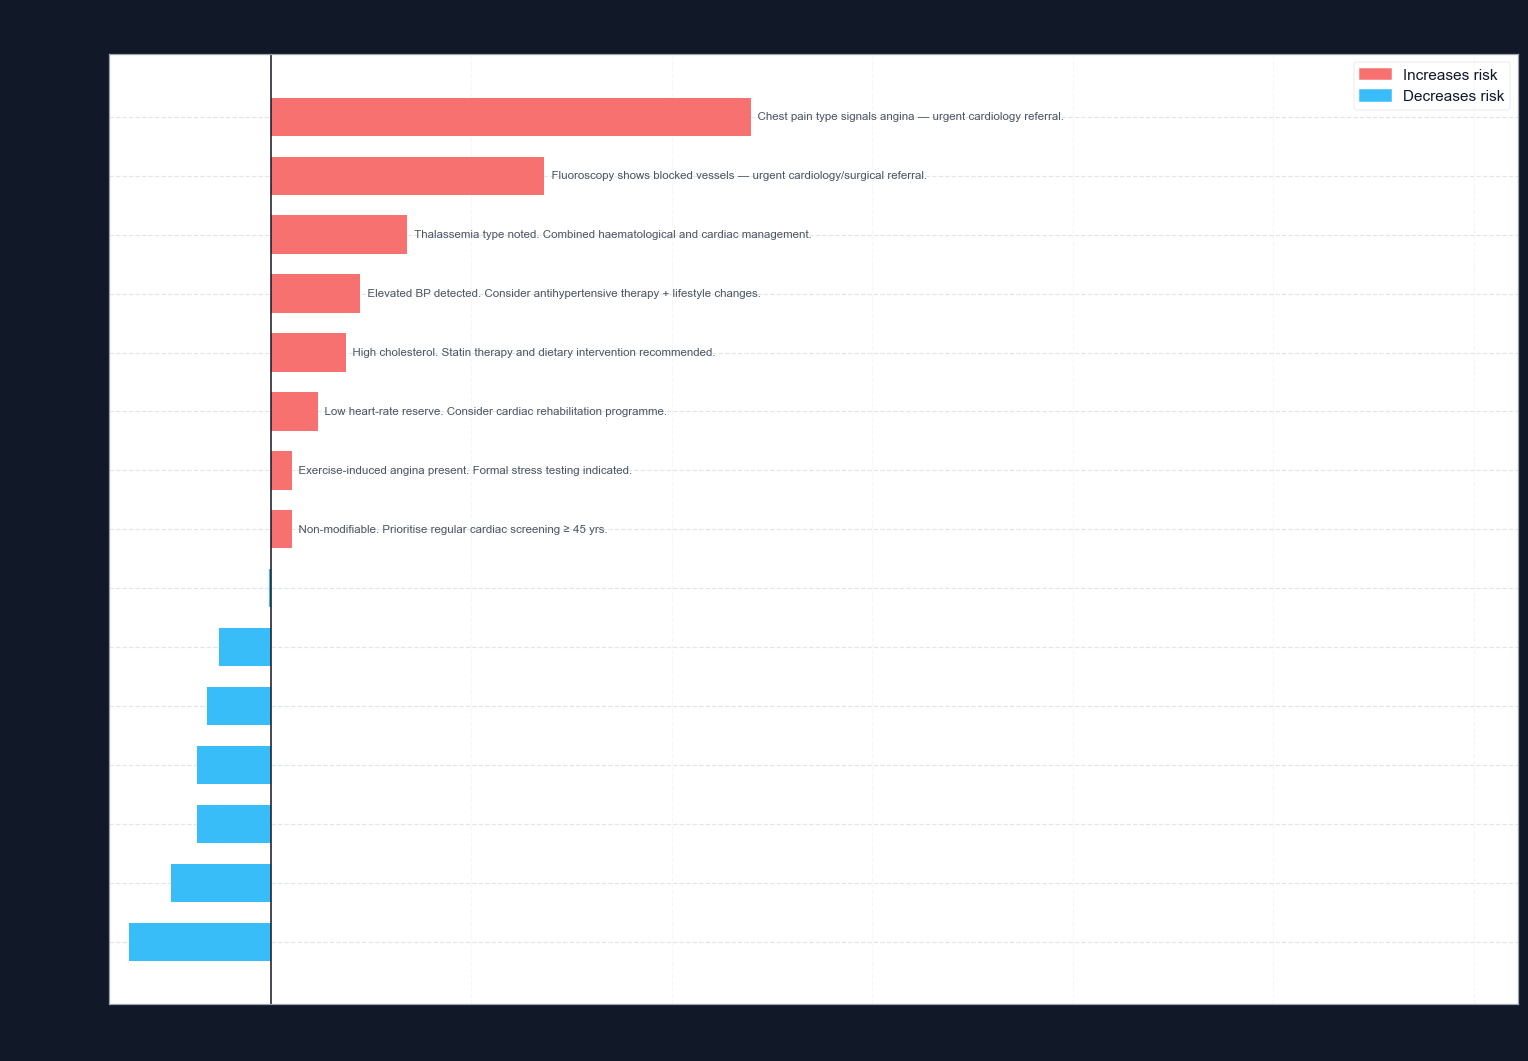

💾 Saved: actionable_explanation_recommendations.png


In [80]:
 # ── Actionable Explanation Visualisation ──────────────────────────────────────
pairs_sorted = sorted(zip(selected_features, shap_values[instance_idx]),
                      key=lambda x: x[1], reverse=True)
feat_names_act = [p[0] for p in pairs_sorted]
shap_vals_act  = [p[1] for p in pairs_sorted]
bar_clrs_act   = ["#f87171" if v > 0 else "#38bdf8" for v in shap_vals_act]
actions_act    = [ACTION_MAP.get(f, "Monitor closely.") if v > 0 else ""
                  for f, v in zip(feat_names_act, shap_vals_act)]

fig, ax = plt.subplots(figsize=(14, max(5, len(feat_names_act) * 0.65)), facecolor=INK)
bars = ax.barh(range(len(feat_names_act)), shap_vals_act,
               color=bar_clrs_act, edgecolor="none", height=0.65)
ax.axvline(0, color=INK, linewidth=1)

ax.set_yticks(range(len(feat_names_act)))
ax.set_yticklabels(feat_names_act, fontsize=10, color=INK)
ax.invert_yaxis()

for i, (val, action) in enumerate(zip(shap_vals_act, actions_act)):
    offset = 0.002 if val >= 0 else -0.002
    ha     = "left" if val >= 0 else "right"
    ax.text(val + offset, i, f"  {action}" if action else "",
            va="center", fontsize=7.5, color="#4b5563", ha=ha, clip_on=True)

ax.set_xlim(min(shap_vals_act) - 0.1, max(shap_vals_act) * 2.6)
ax.set_xlabel("SHAP Value (contribution to disease probability)", fontsize=11)
ax.set_title(
    f"Actionable Explanations — High-Risk Instance #{instance_idx}\n"
    f"Each bar shows how much a feature pushes the prediction toward or away from Disease",
    fontsize=12, fontweight="bold", color=INK
)
ax.legend(handles=[mpatches.Patch(color="#f87171", label="Increases risk"),
                   mpatches.Patch(color="#38bdf8", label="Decreases risk")],
          framealpha=0.3, fontsize=10)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/actionable_explanation_recommendations.png",
            bbox_inches="tight")
plt.show()
print("💾 Saved: actionable_explanation_recommendations.png")

---
## 16. 💾 Model Export

The fitted artefacts below are what the Streamlit app (`app.py`) loads for live inference and explanations.

In [81]:
# ── Persist artefacts for the Streamlit app ──────────────────────────────────
joblib.dump(best_estimators["Stacking"], f"{MODELS_DIR}/stacking_model.joblib")
joblib.dump(best_estimators["XGBoost"],  f"{MODELS_DIR}/xgboost_pipeline.joblib")
joblib.dump(scaler,                       f"{MODELS_DIR}/scaler.joblib")

meta = {
    "all_feature_names": all_feature_names,
    "selected_features": selected_features,
    "continuous_cols":   continuous_cols,
    "shap_expected_value": expected_value,
    "random_state":      RANDOM_STATE,
    "n_train_after_smote": int(X_train_sel.shape[0]),
    "n_test":            int(X_test_sel.shape[0]),
}
with open(f"{MODELS_DIR}/metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

results_df.to_csv(f"{REPORTS_DIR}/model_metrics.csv")
print("✅ Saved:", sorted(os.listdir(MODELS_DIR)), "+ reports/model_metrics.csv")

✅ Saved: ['metadata.json', 'scaler.joblib', 'stacking_model.joblib', 'xgboost_pipeline.joblib'] + reports/model_metrics.csv


---
## 17. 📝 Conclusions & Limitations

* The stacking ensemble (Random Forest + XGBoost + SVM, Logistic Regression meta-learner) is compared against each tuned base model on a stratified, held-out 20 % test split — see the metrics table in Section 12.
* SHAP (global and local) and LIME (local) agree on the dominant clinical drivers, and SHAP values are translated into actionable recommendations (Section 15).
* **Small test set.** After removing duplicate rows only 302 unique patients remain, so the test split holds ~61 patients; one misclassification moves accuracy by ≈1.6 pp. Treat point estimates with caution.
* **CV optimism.** SMOTE, scaling and RFECV are fitted before cross-validation inside the training split, so the CV AUC figures in Sections 9–12 are optimistic. The held-out test set is untouched by resampling and is the reliable estimate.
* **Dataset coding quirk.** In this Kaggle copy of the data several codings behave opposite to the textbook UCI description (e.g. fewer coloured vessels, `ca = 0`, and male sex are associated with *lower* disease probability in SHAP/LIME). The model faithfully learns the dataset, so explanations and the clinical action text should be read as properties of this dataset, not as clinical facts.
* **Not a medical device.** This is an academic prototype trained on a public dataset; it must not be used for clinical decisions.

In [82]:
# ── Summary: All Saved Figures ────────────────────────────────────────────────
saved = sorted(os.listdir(FIGURES_DIR))
print(f"\n📁 {len(saved)} figures saved in ./{FIGURES_DIR}/")
print("=" * 55)
for f in saved:
    size_kb = os.path.getsize(f"{FIGURES_DIR}/{f}") // 1024
    print(f"  ✅  {f:<55s}  ({size_kb} KB)")


📁 23 figures saved in ./figures/
  ✅  EDA_pairplot_key_features.png                            (376 KB)
  ✅  EDA_violin_plots.png                                     (164 KB)
  ✅  LIME_local_explanation_high_risk.png                     (93 KB)
  ✅  LIME_local_explanation_low_risk.png                      (94 KB)
  ✅  RFECV_cross_validation_scores_plot.png                   (75 KB)
  ✅  ROC_curves_all_models.png                                (74 KB)
  ✅  SHAP_dependence_plot.png                                 (44 KB)
  ✅  SHAP_global_feature_importance_bar_plot.png              (81 KB)
  ✅  SHAP_summary_beeswarm_plot.png                           (128 KB)
  ✅  SHAP_waterfall_single_prediction.png                     (120 KB)
  ✅  actionable_explanation_recommendations.png               (130 KB)
  ✅  categorical_features_vs_target.png                       (124 KB)
  ✅  class_distribution.png                                   (42 KB)
  ✅  confusion_matrices_all_models.png            